Imported packages relevant to the model, used pandas to load the dataset from the csv file.

In [6]:
%pip install pandas numpy matplotlib seaborn geopandas

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd

df = pd.read_csv('data/Marine_Microplastics.csv')
df.head()


[notice] A new release of pip available: 22.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


,OBJECTID,Oceans,Regions,SubRegions,Sampling Method,Measurement,Unit,Density Range,Density Class,Short Reference,...,Organization,Keywords,Accession Number,Accession Link,Latitude,Longitude,Date,GlobalID,x,y
0,9676,Atlantic Ocean,NaN,NaN,Grab sample,0.018,pieces/m3,0.005-1,Medium,Barrows et al.2018,...,Adventure Scientist,Adventure Scientist/Citizen Science,211009,https://www.ncei.noaa.gov/access/metadata/land...,-31.696000,-48.560000,08/11/2015 00:00,a77121b2-e113-444e-82d9-7af11d62fdd2,-48.560000,-31.696000
1,6427,Pacific Ocean,NaN,NaN,Neuston net,0.000,pieces/m3,0-0.0005,Very Low,Law et al.2014,...,Sea Education Association,SEA,211008,https://www.ncei.noaa.gov/access/metadata/land...,6.350000,-121.850000,12/18/2002 12:00:00 AM,be27c450-02ca-4261-8d89-cae21108e6cc,-121.850000,6.350000
2,10672,Pacific Ocean,NaN,NaN,Manta net,0.013,pieces/m3,0.005-1,Medium,Goldstein et al.2013,...,Scripps Institution of Oceanography-University...,Great Pacific Garbage Patch/SEAPLEX,253448,https://www.ncei.noaa.gov/access/metadata/land...,0.500000,-95.350000,10/17/2006 12:00:00 AM,23effcdd-35b7-4e1e-adb4-390693a287d3,-95.350000,0.500000
3,13921,Atlantic Ocean,NaN,NaN,Aluminum bucket,1368.000,pieces/m3,>=10,Very High,Queiroz et al.2022,...,"Federal University of Pará, Brazil",Amazon Continental Shelf,276482,https://www.ncei.noaa.gov/access/metadata/land...,0.631825,-45.398158,10/17/2018 12:00:00 AM,16d77822-0533-4116-97b9-0bdb592f3d6e,-45.398158,0.631825
4,9344,Pacific Ocean,NaN,NaN,Grab sample,0.001,pieces/m3,0.0005-0.005,Low,Barrows et al.2018,...,Adventure Scientist,Adventure Scientist/Citizen Science,211009,https://www.ncei.noaa.gov/access/metadata/land...,16.623000,-99.697800,01/03/2015 00:00,b9e435e3-9e86-4143-8b51-877e5dcdc7a6,-99.697800,16.623000


Conducted statistical analysis on dataset.

In [9]:
df.shape
df.columns
df.info()
df.isnull().sum()
df.duplicated().sum()

pd.set_option("display.float_format", "{:.2f}".format)

print("Measurement column statistics:")
print(df["Measurement"].describe())


<class 'pandas.DataFrame'>
RangeIndex: 20425 entries, 0 to 20424
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   OBJECTID          20425 non-null  int64  
 1   Oceans            20154 non-null  str    
 2   Regions           8885 non-null   str    
 3   SubRegions        1307 non-null   str    
 4   Sampling Method   20425 non-null  str    
 5   Measurement       14613 non-null  float64
 6   Unit              20425 non-null  str    
 7   Density Range     20425 non-null  str    
 8   Density Class     20425 non-null  str    
 9   Short Reference   20425 non-null  str    
 10  Long Reference    20425 non-null  str    
 11  DOI               20425 non-null  str    
 12  Organization      20425 non-null  str    
 13  Keywords          20407 non-null  str    
 14  Accession Number  20425 non-null  int64  
 15  Accession Link    20425 non-null  str    
 16  Latitude          20425 non-null  float64
 17  Long

In [10]:
#Cleaning

df_clean = df.copy().drop_duplicates()
print("Rows after removing duplicates:", len(df_clean))
df.shape
#there are no duplicates


Rows after removing duplicates: 20425


(20425, 22)

In [11]:
#Removing the columns we don't want
df_clean = df_clean.drop(columns=["Density Range", "Long Reference", "DOI", "Short Reference", "Organization", "Keywords", "Accession Number", "Accession Link", "GlobalID", "x", "y"])


In [12]:
df_clean.head()

,OBJECTID,Oceans,Regions,SubRegions,Sampling Method,Measurement,Unit,Density Class,Latitude,Longitude,Date
0,9676,Atlantic Ocean,NaN,NaN,Grab sample,0.02,pieces/m3,Medium,-31.70,-48.56,08/11/2015 00:00
1,6427,Pacific Ocean,NaN,NaN,Neuston net,0.00,pieces/m3,Very Low,6.35,-121.85,12/18/2002 12:00:00 AM
2,10672,Pacific Ocean,NaN,NaN,Manta net,0.01,pieces/m3,Medium,0.50,-95.35,10/17/2006 12:00:00 AM
3,13921,Atlantic Ocean,NaN,NaN,Aluminum bucket,1368.00,pieces/m3,Very High,0.63,-45.40,10/17/2018 12:00:00 AM
4,9344,Pacific Ocean,NaN,NaN,Grab sample,0.00,pieces/m3,Low,16.62,-99.70,01/03/2015 00:00


In [13]:
df_clean.isna().sum()

OBJECTID               0
Oceans               271
Regions            11540
SubRegions         19118
Sampling Method        0
Measurement         5812
Unit                   0
Density Class          0
Latitude               0
Longitude              0
Date                   0
dtype: int64

Created countplots for Oceans and Sampling Method

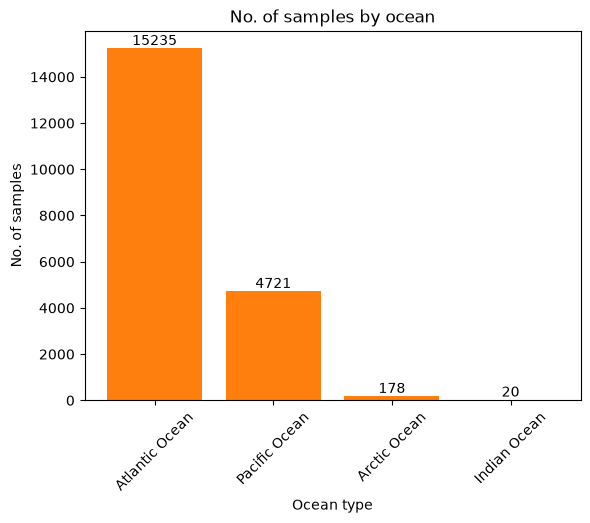

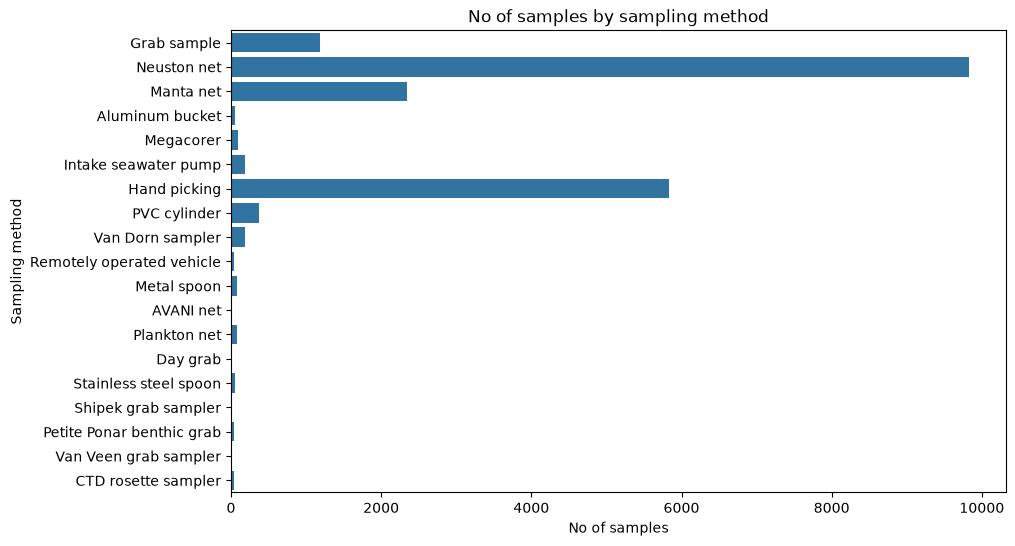

In [14]:
pd.set_option("display.float_format", "{:.2f}".format)
df.describe()

df["Oceans"].value_counts()
sns.countplot(data=df, x="Oceans")

plt.title("No. of samples by ocean")
plt.xlabel("Ocean type")
plt.ylabel("No. of samples")
plt.xticks(rotation=45)

plt.bar_label(plt.bar(df["Oceans"].value_counts().index, df["Oceans"].value_counts().values))

plt.show()


df["Sampling Method"].value_counts()
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    y="Sampling Method"
)

plt.title("No of samples by sampling method")
plt.xlabel("No of samples")
plt.ylabel("Sampling method")

plt.show()

In [15]:
#To attribute an ocean for the missing values : using nearest neighbors

known = df_clean[df_clean["Oceans"].notna()]
missing = df_clean[df_clean["Oceans"].isna()]

for i, row in missing.iterrows():

    distances = ( (known["Latitude"] - row["Latitude"]) ** 2 + (known["Longitude"] - row["Longitude"]) ** 2 ) #calculating the distance between each know points and the one we are looking for

    nearest_index = distances.idxmin() #choosing the index with the lowest score in distance

    df_clean.loc[i, "Oceans"] = known.loc[nearest_index, "Oceans"] #affecting the ocean to the database


In [16]:
#To attribute a region for the missing values : using nearest neighbors

known = df_clean[df_clean["Regions"].notna()]
missing = df_clean[df_clean["Regions"].isna()]

for i, row in missing.iterrows():

    distances = ( (known["Latitude"] - row["Latitude"]) ** 2 + (known["Longitude"] - row["Longitude"]) ** 2 ) 
    
    nearest_index = distances.idxmin()

    df_clean.loc[i, "Regions"] = known.loc[nearest_index, "Regions"]


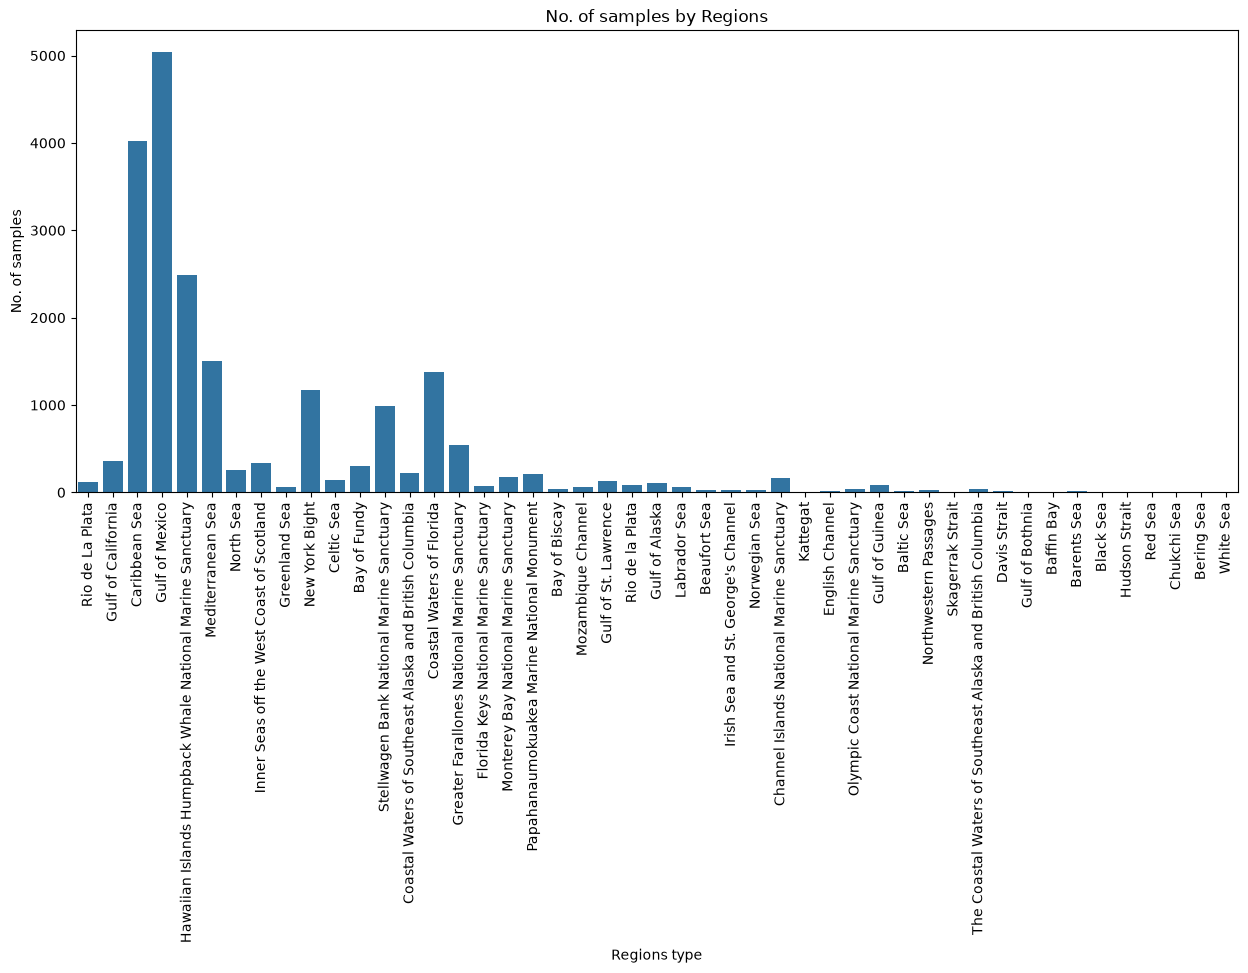

In [17]:
#No. of samples by Regions 

pd.set_option("display.float_format", "{:.2f}".format)
df.describe()

df["Regions"].value_counts()

plt.figure(figsize=(15, 6))

sns.countplot(data=df_clean, x="Regions")

plt.title("No. of samples by Regions")
plt.xlabel("Regions type")
plt.ylabel("No. of samples")
plt.xticks(rotation=90)

plt.tight_layout
plt.show()

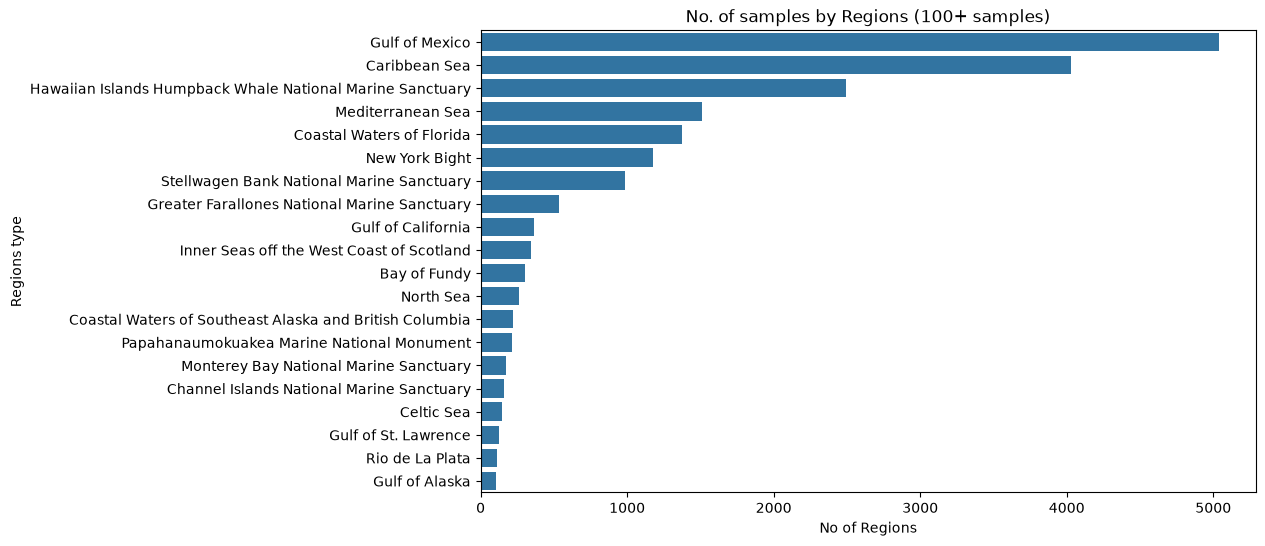

In [18]:
#No. of samples by Regions, but limiting the regions that have at least 100 samples to show up

counts = df_clean["Regions"].value_counts()
counts = counts[counts >= 100]
counts = counts.sort_values(ascending=False)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=counts.values,
    y=counts.index
)

plt.title("No. of samples by Regions (100+ samples)")
plt.xlabel("No of Regions")
plt.ylabel("Regions type")

plt.show()

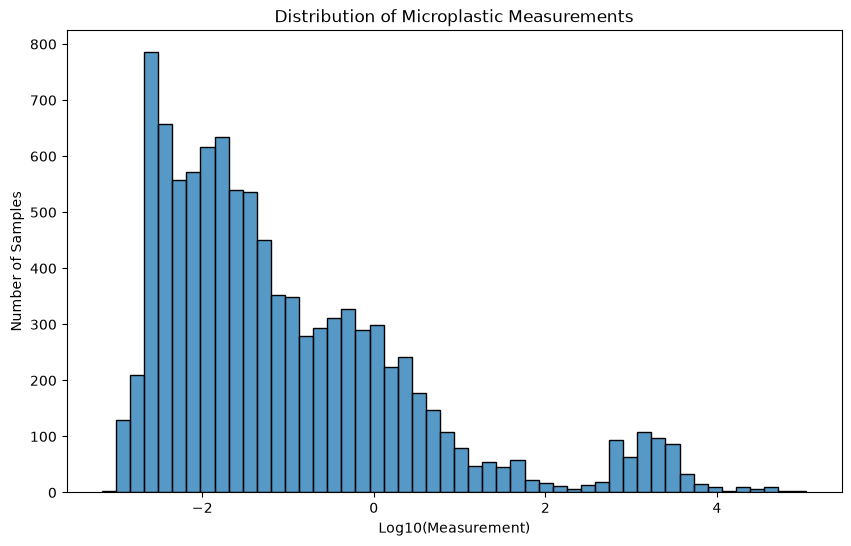


[notice] A new release of pip available: 22.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [19]:
#cell 1
measurements = df["Measurement"].dropna()
measurements = measurements[measurements > 0]

plt.figure(figsize=(10, 6))

sns.histplot(
    x=np.log10(measurements),
    bins=50
)

plt.title("Distribution of Microplastic Measurements")
plt.xlabel("Log10(Measurement)")
plt.ylabel("Number of Samples")

plt.show()



#cell 2
%pip install folium


#cell 3
import folium
from folium.plugins import HeatMap
from IPython.display import display


# Keep rows with valid locations and recorded measurements
map_data = df.dropna(
    subset=["Latitude", "Longitude", "Measurement"]
).copy()

# Keep positive measurements for the heatmap
map_data = map_data[map_data["Measurement"] > 0]

# Reduce the effect of extremely large measurements
map_data["HeatWeight"] = np.log1p(map_data["Measurement"])

# Create a world map
world_map = folium.Map(
    location=[20, 0],
    zoom_start=2,
    tiles="OpenStreetMap"
)
# Add the microplastic hotspots
HeatMap(
    map_data[["Latitude", "Longitude", "HeatWeight"]].values.tolist(),
    radius=12,
    blur=18,
    max_zoom=4
).add_to(world_map)

display(world_map)

# Save an interactive copy
world_map.save("microplastic_hotspots.html")




             



In [23]:
import pandas as pd

df = pd.read_csv("data/Marine_Microplastics.csv")

print(df.head())

   OBJECTID          Oceans Regions SubRegions  Sampling Method  Measurement  \
0      9676  Atlantic Ocean     NaN        NaN      Grab sample         0.02   
1      6427   Pacific Ocean     NaN        NaN      Neuston net         0.00   
2     10672   Pacific Ocean     NaN        NaN        Manta net         0.01   
3     13921  Atlantic Ocean     NaN        NaN  Aluminum bucket      1368.00   
4      9344   Pacific Ocean     NaN        NaN      Grab sample         0.00   

        Unit Density Range Density Class       Short Reference  ...  \
0  pieces/m3       0.005-1        Medium    Barrows et al.2018  ...   
1  pieces/m3      0-0.0005      Very Low        Law et al.2014  ...   
2  pieces/m3       0.005-1        Medium  Goldstein et al.2013  ...   
3  pieces/m3          >=10     Very High    Queiroz et al.2022  ...   
4  pieces/m3  0.0005-0.005           Low    Barrows et al.2018  ...   

                                        Organization  \
0                                Adv

In [24]:
# Gets the first and last observation of the time variable. as well as the maximum number of observations in the dataset.
print("First observation:", ds.time.values[0]) 
print("Last observation:", ds.time.values[-1])
print("Number of observations:", len(ds.time))

NameError: name 'ds' is not defined

In [15]:
# Calculate the time difference between the first two observations in hours
time_difference = ds.time.values[1] - ds.time.values[0]

print("Time interval:", time_difference / np.timedelta64(1, 'h'), "hours")

Time interval: 24.0 hours


In [16]:
# Get the first observation of latitude and longitude for each particle in the dataset
start_lat = ds.lat.isel(obs=0)
start_lon = ds.lon.isel(obs=0)

# Print the range of the first observation of latitude and longitude
print("Starting latitude range:", 
      float(start_lat.min()), float(start_lat.max()))

print("Starting longitude range:", 
      float(start_lon.min()), float(start_lon.max()))

Starting latitude range: -55.36840057373047 69.87090301513672
Starting longitude range: -175.53689575195312 179.35499572753906


In [17]:
# Create a mask for particles that start in the Atlantic Ocean
atlantic_mask = (
    (start_lat >= -60) &
    (start_lat <= 70) &
    (start_lon >= -100) &
    (start_lon <= 20)
)

# Print the total number of particles and the number of particles that start in the Atlantic Ocean
print("Total particles:", ds.sizes["traj"])
print("Particles starting in Atlantic:", int(atlantic_mask.sum()))

Total particles: 387600
Particles starting in Atlantic: 9306


In [18]:
# Create a new dataset that only contains particles that start in the Atlantic Ocean
atlantic_ds = ds.isel(traj=atlantic_mask)

print(atlantic_ds)

<xarray.Dataset> Size: 55MB
Dimensions:  (traj: 9306, obs: 733)
Coordinates:
    time     (obs) datetime64[ns] 6kB 2020-01-01 2020-01-02 ... 2022-01-02
Dimensions without coordinates: traj, obs
Data variables:
    lon      (traj, obs) float32 27MB ...
    lat      (traj, obs) float32 27MB ...
Attributes:
    title:         Global Marine Litter trajectories
    description:   Combined monthly releases of 32300 particles for 2020.
    institution:   FLorida State University Center for Ocean-Atmospheric Pred...
    references:    Chassignet, E. P., Xu, X., & Zavala-Romero, O. (2021), Tra...
    date_created:  2022-03-08T17:21:58.252213


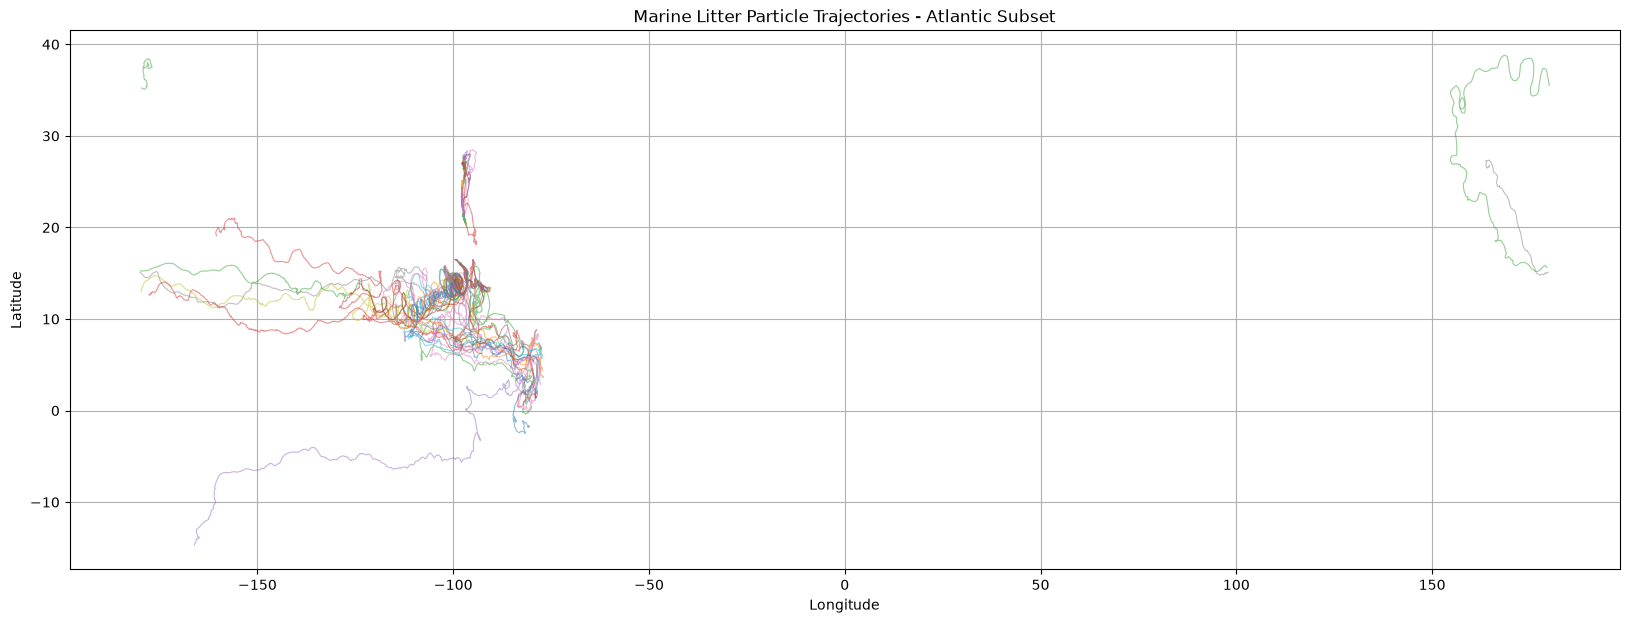

In [19]:
plt.figure(figsize=(20, 7))

sample = atlantic_ds

for i in range(50):
    lon = sample.lon.values[i, :].copy()
    lat = sample.lat.values[i, :].copy()

    # Break lines when particles cross the International Date Line
    jumps = np.where(np.abs(np.diff(lon)) > 180)[0] + 1

    lon[jumps] = np.nan
    lat[jumps] = np.nan

    plt.plot(lon, lat, alpha=0.5, linewidth=0.8)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Marine Litter Particle Trajectories - Atlantic Subset")
plt.grid()
plt.show()

In [20]:
# Get all particle coordinates
lat = ds.lat.values
lon = ds.lon.values

# Identify valid positions
valid = np.isfinite(lat) & np.isfinite(lon)

# Find the first valid observation for each particle
first_indices = valid.argmax(axis=1)

particle_indices = np.arange(ds.sizes["traj"])

# Extract each particle's starting coordinates
start_lat_all = lat[particle_indices, first_indices]
start_lon_all = lon[particle_indices, first_indices]

# Exclude particles without valid positions
has_data = valid.any(axis=1)

# Identify particles starting in the Atlantic
atlantic_mask_all = (
    has_data &
    (start_lat_all >= -60) &
    (start_lat_all <= 70) &
    (start_lon_all >= -100) &
    (start_lon_all <= 20)
)

print("Total particles:", ds.sizes["traj"])
print("Particles starting in Atlantic:", int(atlantic_mask_all.sum()))

Total particles: 387600
Particles starting in Atlantic: 111672


In [21]:
atlantic_ds_valid = ds.isel(traj=atlantic_mask_all)

print(atlantic_ds_valid)

<xarray.Dataset> Size: 655MB
Dimensions:  (traj: 111672, obs: 733)
Coordinates:
    time     (obs) datetime64[ns] 6kB 2020-01-01 2020-01-02 ... 2022-01-02
Dimensions without coordinates: traj, obs
Data variables:
    lon      (traj, obs) float32 327MB -99.5 -99.24 -98.98 ... -49.7 -49.71
    lat      (traj, obs) float32 327MB 16.48 16.49 16.42 ... 0.02313 0.02841
Attributes:
    title:         Global Marine Litter trajectories
    description:   Combined monthly releases of 32300 particles for 2020.
    institution:   FLorida State University Center for Ocean-Atmospheric Pred...
    references:    Chassignet, E. P., Xu, X., & Zavala-Romero, O. (2021), Tra...
    date_created:  2022-03-08T17:21:58.252213


In [22]:
# Extract particle coordinates
atlantic_lat = atlantic_ds_valid.lat.values
atlantic_lon = atlantic_ds_valid.lon.values

atlantic_valid = np.isfinite(atlantic_lat) & np.isfinite(atlantic_lon)

start_lat = start_lat_all[atlantic_mask_all]
start_lon = start_lon_all[atlantic_mask_all]

# Correct longitude differences across the International Date Line
dlon = np.radians(
    (atlantic_lon - start_lon[:, None] + 180) % 360 - 180
)

dlat = np.radians(atlantic_lat) - np.radians(start_lat[:, None])

a = (np.sin(dlat / 2)**2 +
     np.cos(np.radians(start_lat[:, None])) *
     np.cos(np.radians(atlantic_lat)) *
     np.sin(dlon / 2)**2)

displacement = 6371 * 2 * np.arctan2(
    np.sqrt(a),
    np.sqrt(1 - a)
)

displacement[~atlantic_valid] = np.nan

print("Number of particles:", len(displacement))
print("Displacement array shape:", displacement.shape)
print("Valid starting positions:", atlantic_valid.any(axis=1).sum())

Number of particles: 111672
Displacement array shape: (111672, 733)
Valid starting positions: 111672


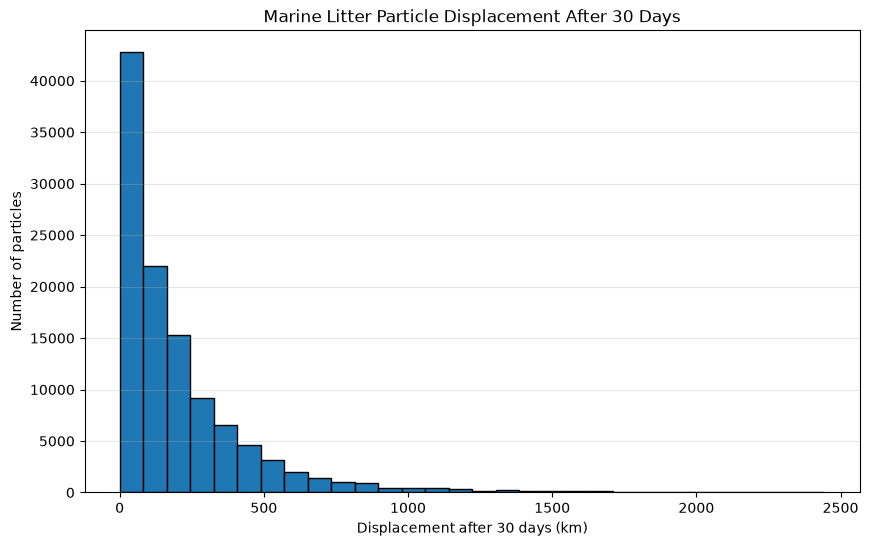

In [23]:
atlantic_first_indices = atlantic_valid.argmax(axis=1)

# Select displacement 30 days after each particle's release
target_indices = atlantic_first_indices + 30

# Keep particles with a valid observation 30 days later
available = target_indices < atlantic_ds_valid.sizes["obs"]

particle_ids = np.arange(len(atlantic_first_indices))[available]
target_days = target_indices[available]

valid_30 = atlantic_valid[particle_ids, target_days]

distance_30 = displacement[particle_ids[valid_30],
                            target_days[valid_30]]

# Plot histogram
plt.figure(figsize=(10, 6))

plt.hist(distance_30, bins=30, edgecolor="black")

plt.xlabel("Displacement after 30 days (km)")
plt.ylabel("Number of particles")
plt.title("Marine Litter Particle Displacement After 30 Days")

plt.grid(axis="y", alpha=0.3)
plt.show()

Day 0 average per occupied hexagon: 191.7
Day 30 average per occupied hexagon: 60.66


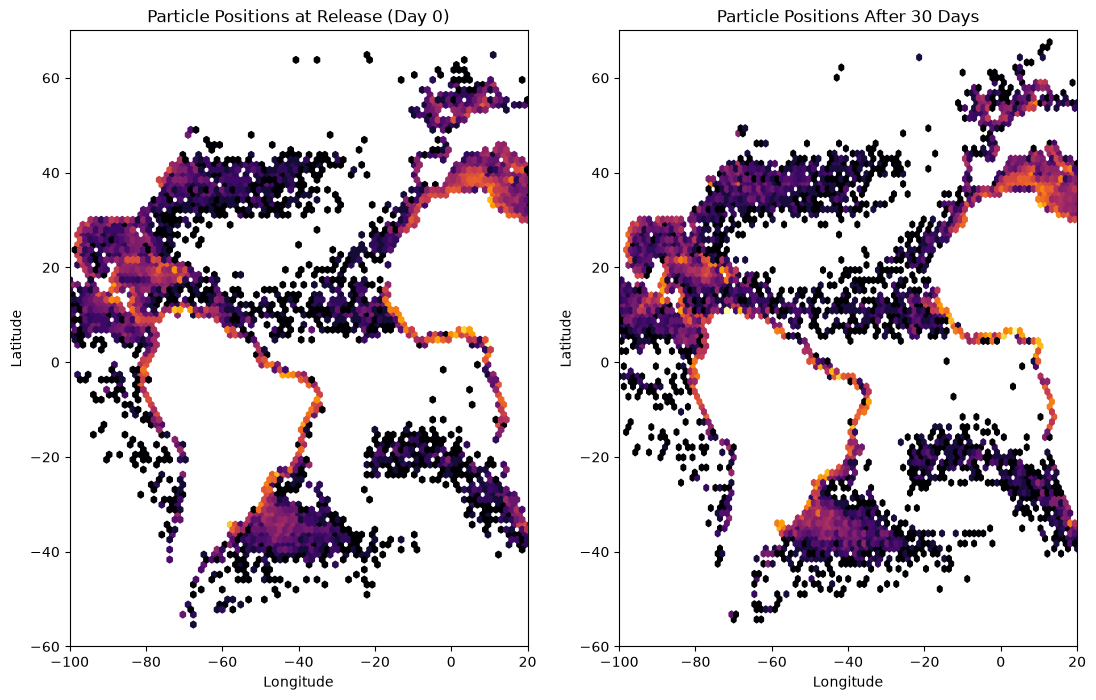

In [24]:
lat_0= lat[particle_ids, atlantic_first_indices[particle_ids]]
lon_0 = lon[particle_ids, atlantic_first_indices[particle_ids]]

# Get particle positions 30 days after release
lon_30 = lon[particle_ids, target_days]
lat_30 = lat[particle_ids, target_days]

# Keep positions within our Atlantic study region
atlantic_region = (
    (lon_30 >= -100) & (lon_30 <= 20) &
    (lat_30 >= -60) & (lat_30 <= 70)
)

lon_plot_0 = lon_0[atlantic_region]
lat_plot_0 = lat_0[atlantic_region]

lon_plot_30 = lon_30[atlantic_region]
lat_plot_30 = lat_30[atlantic_region]

fig,axes = plt.subplots(1, 2,figsize=(13, 8))

#Day 0
hb1 = axes[0].hexbin(
    lon_plot_0,
    lat_plot_0,
    gridsize=100,
    mincnt=1,
    bins='log',
    cmap='inferno'
    
)

axes[0].set_title("Particle Positions at Release (Day 0)")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
axes[0].set_xlim(-100, 20)
axes[0].set_ylim(-60, 70)

hb2 = axes[1].hexbin(
    lon_plot_30,
    lat_plot_30,
    gridsize=100,
    mincnt=1,
    bins='log',
    cmap='inferno'
)

axes[1].set_title("Particle Positions After 30 Days")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")
axes[1].set_xlim(-100, 20)
axes[1].set_ylim(-60, 70)

print("Day 0 average per occupied hexagon:",
      round(111185 / 580, 2))

print("Day 30 average per occupied hexagon:",
      round(111185 / 1833, 2))

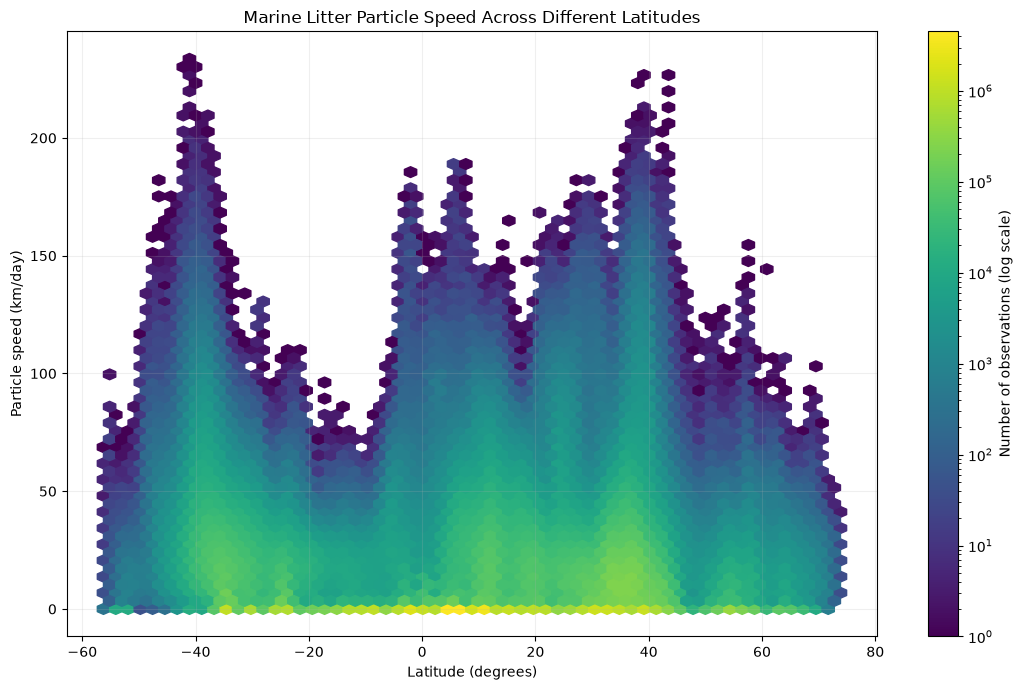

In [25]:
# Coordinates on consecutive days
lat1 = np.radians(atlantic_lat[:, :-1])
lat2 = np.radians(atlantic_lat[:, 1:])

lon1 = np.radians(atlantic_lon[:, :-1])
lon2 = np.radians(atlantic_lon[:, 1:])

# Calculate daily coordinate differences
dlat = lat2 - lat1
dlon = (lon2 - lon1 + np.pi) % (2 * np.pi) - np.pi

# Haversine distance between consecutive positions
a = (np.sin(dlat / 2)**2 +
     np.cos(lat1) * np.cos(lat2) *
     np.sin(dlon / 2)**2)

daily_distance = 6371 * 2 * np.arctan2(
    np.sqrt(a),
    np.sqrt(1 - a)
)

# Only use consecutive valid positions
valid_pairs = atlantic_valid[:, :-1] & atlantic_valid[:, 1:]

daily_speed = daily_distance[valid_pairs]

# Latitude halfway between consecutive observations
mid_lat = (atlantic_lat[:, :-1] + atlantic_lat[:, 1:]) / 2
speed_lat = mid_lat[valid_pairs]

# Remove invalid values
keep = np.isfinite(daily_speed) & np.isfinite(speed_lat)

daily_speed = daily_speed[keep]
speed_lat = speed_lat[keep]

# Plot speed against latitude
plt.figure(figsize=(11, 7))

plt.hexbin(
    speed_lat,
    daily_speed,
    gridsize=60,
    bins="log",
    mincnt=1,
    cmap="viridis"
)

plt.colorbar(label="Number of observations (log scale)")
plt.xlabel("Latitude (degrees)")
plt.ylabel("Particle speed (km/day)")
plt.title("Marine Litter Particle Speed Across Different Latitudes")

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

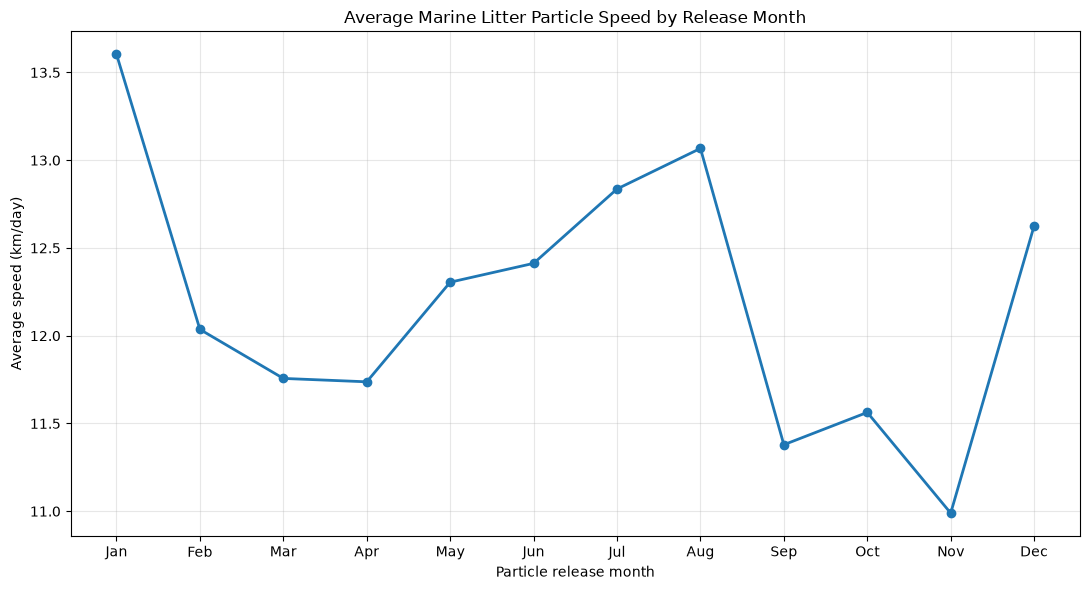

In [26]:
# Calculate average speed during the first 30 days
monthly_speeds = {}
release_months = []

for i in range(len(atlantic_first_indices)):

    start = atlantic_first_indices[i]

    if start + 30 < atlantic_ds.sizes["obs"]:

        speeds = daily_distance[i, start:start + 30]
        pair_valid = valid_pairs[i, start:start + 30]

        usable_speeds = speeds[pair_valid]

        if len(usable_speeds) >= 25:
            monthly_speeds.setdefault(
                int(pd.Timestamp(ds.time.values[start]).month), []
            ).append(np.mean(usable_speeds))

# Calculate monthly averages
months = list(range(1, 13))

average_speeds = [
    np.mean(monthly_speeds[m]) if m in monthly_speeds else np.nan
    for m in months
]

# Plot
plt.figure(figsize=(11, 6))

plt.plot(
    months,
    average_speeds,
    marker="o",
    linewidth=2
)

plt.xticks(months, [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
])

plt.xlabel("Particle release month")
plt.ylabel("Average speed (km/day)")
plt.title("Average Marine Litter Particle Speed by Release Month")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

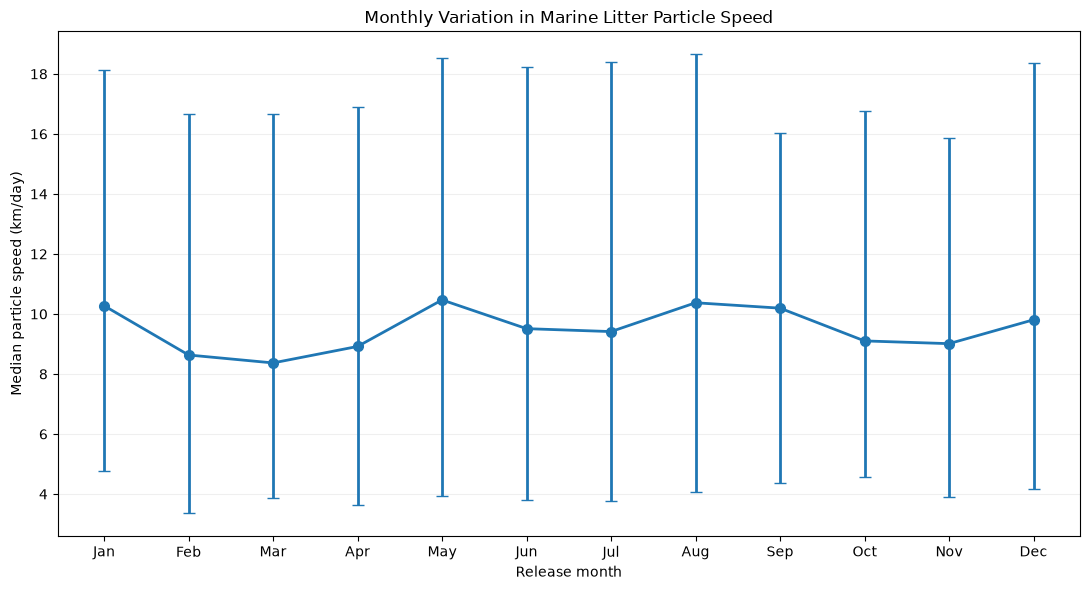

In [27]:
monthly_medians = [
    np.median(monthly_speeds[m]) for m in range(1, 13)
]

monthly_q1 = [
    np.percentile(monthly_speeds[m], 25) for m in range(1, 13)
]

monthly_q3 = [
    np.percentile(monthly_speeds[m], 75) for m in range(1, 13)
]

lower_error = np.array(monthly_medians) - np.array(monthly_q1)
upper_error = np.array(monthly_q3) - np.array(monthly_medians)

plt.figure(figsize=(11, 6))

plt.errorbar(
    range(1, 13),
    monthly_medians,
    yerr=[lower_error, upper_error],
    fmt='o-',
    markersize=7,
    linewidth=2,
    capsize=4
)

plt.xticks(
    range(1, 13),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.xlabel("Release month")
plt.ylabel("Median particle speed (km/day)")
plt.title("Monthly Variation in Marine Litter Particle Speed")

plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

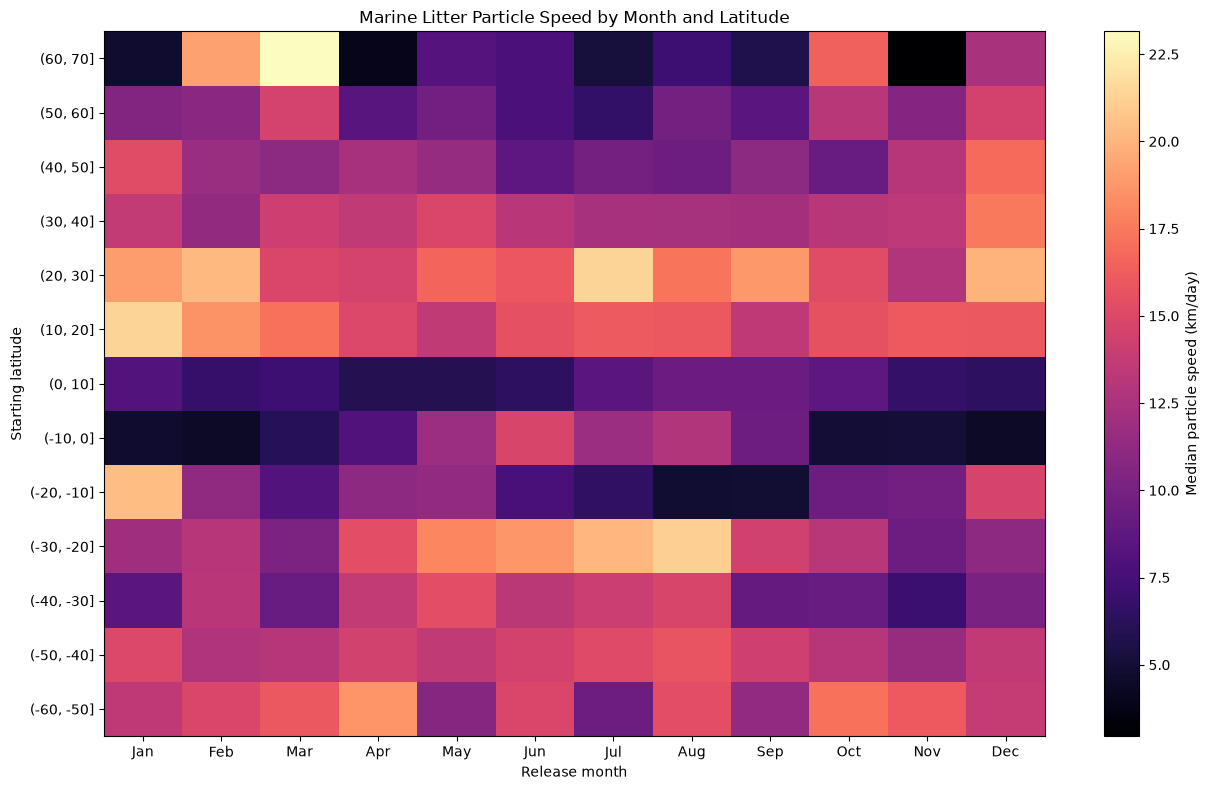

In [28]:
# Calculate average speed during each particle's first 30 days
records = []

for i in range(len(atlantic_first_indices)):

    start = atlantic_first_indices[i]
    end = start + 30

    if end < atlantic_ds_valid.sizes["obs"]:

        speeds = daily_distance[i, start:end]
        pair_valid = valid_pairs[i, start:end]

        usable = speeds[pair_valid]

        if len(usable) >= 25:

            records.append({
                "Month": pd.Timestamp(
                    atlantic_ds_valid.time.values[start]
                ).month,
                "Latitude": start_lat[i],
                "Speed": np.mean(usable)
            })

# Convert results into a DataFrame
speed_df = pd.DataFrame(records)

# Group latitude into 10-degree bands
speed_df["Latitude band"] = pd.cut(
    speed_df["Latitude"],
    bins=np.arange(-60, 81, 10)
)

# Calculate median speed for each month and latitude band
heatmap_data = speed_df.pivot_table(
    index="Latitude band",
    columns="Month",
    values="Speed",
    observed=False
)

# Plot heatmap
plt.figure(figsize=(13, 8))

plt.imshow(
    heatmap_data,
    aspect="auto",
    origin="lower",
    cmap="magma",
    interpolation="nearest"
)

plt.colorbar(label="Median particle speed (km/day)")

plt.xticks(
    range(12),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.yticks(
    range(len(heatmap_data.index)),
    heatmap_data.index.astype(str)
)

plt.xlabel("Release month")
plt.ylabel("Starting latitude")
plt.title("Marine Litter Particle Speed by Month and Latitude")

plt.tight_layout()
plt.show()

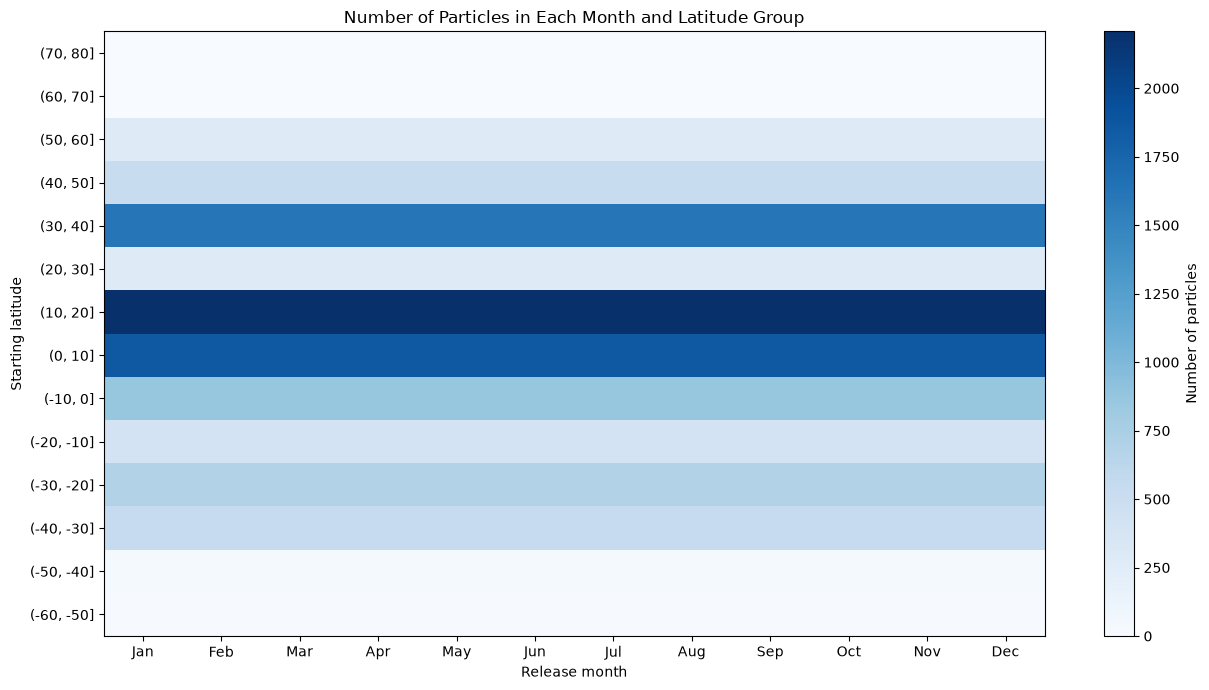

In [29]:
# Count particles in each month and latitude band
count_data = speed_df.pivot_table(
    index="Latitude band",
    columns="Month",
    values="Speed",
    aggfunc="count",
    observed=False
)

plt.figure(figsize=(13, 7))

plt.imshow(
    count_data,
    aspect="auto",
    origin="lower",
    cmap="Blues"
)

plt.colorbar(label="Number of particles")

plt.xticks(
    range(12),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.yticks(
    range(len(count_data.index)),
    count_data.index.astype(str)
)

plt.xlabel("Release month")
plt.ylabel("Starting latitude")
plt.title("Number of Particles in Each Month and Latitude Group")

plt.tight_layout()
plt.show()

In [31]:
print("Time coverage:", currents.time.values)
print("Variables:", list(currents.data_vars))

print("\nMissing values:")
print(currents[["uo", "vo"]].isnull().sum())

print("\nDepth:")
print(currents.depth.values)

print("\nLatitude range:",
      float(currents.latitude.min()),
      "to",
      float(currents.latitude.max()))

print("\nLongitude range:",
      float(currents.longitude.min()),
      "to",
      float(currents.longitude.max()))

Time coverage: ['2020-01-01T00:00:00.000000000' '2020-02-01T00:00:00.000000000'
 '2020-03-01T00:00:00.000000000' '2020-04-01T00:00:00.000000000'
 '2020-05-01T00:00:00.000000000' '2020-06-01T00:00:00.000000000'
 '2020-07-01T00:00:00.000000000' '2020-08-01T00:00:00.000000000'
 '2020-09-01T00:00:00.000000000' '2020-10-01T00:00:00.000000000'
 '2020-11-01T00:00:00.000000000' '2020-12-01T00:00:00.000000000'
 '2021-01-01T00:00:00.000000000' '2021-02-01T00:00:00.000000000'
 '2021-03-01T00:00:00.000000000' '2021-04-01T00:00:00.000000000'
 '2021-05-01T00:00:00.000000000' '2021-06-01T00:00:00.000000000'
 '2021-07-01T00:00:00.000000000' '2021-08-01T00:00:00.000000000'
 '2021-09-01T00:00:00.000000000' '2021-10-01T00:00:00.000000000'
 '2021-11-01T00:00:00.000000000' '2021-12-01T00:00:00.000000000'
 '2022-01-01T00:00:00.000000000']
Variables: ['uo', 'vo']

Missing values:
<xarray.Dataset> Size: 16B
Dimensions:  ()
Data variables:
    uo       int64 8B 1700850
    vo       int64 8B 1700850
Attributes:

In [32]:
# Remove the unnecessary single depth dimension
uo = currents["uo"].squeeze("depth")
vo = currents["vo"].squeeze("depth")

# Calculate total current speed (m/s)
speed = np.sqrt(uo**2 + vo**2)

# Create cleaned dataset
clean_currents = xr.Dataset({
    "uo": uo,
    "vo": vo,
    "speed": speed
})

# Check results
print(clean_currents)

print("\nCurrent speed statistics:")
print("Minimum:", float(speed.min().compute()), "m/s")
print("Maximum:", float(speed.max().compute()), "m/s")
print("Mean:", float(speed.mean().compute()), "m/s")

<xarray.Dataset> Size: 121MB
Dimensions:    (time: 25, latitude: 481, longitude: 840)
Coordinates:
  * time       (time) datetime64[ns] 200B 2020-01-01 2020-02-01 ... 2022-01-01
  * latitude   (latitude) float32 2kB 10.0 10.08 10.17 ... 49.83 49.92 50.0
  * longitude  (longitude) float32 3kB -70.0 -69.92 -69.83 ... -0.1667 -0.08332
    depth      float32 4B 0.494
Data variables:
    uo         (time, latitude, longitude) float32 40MB nan nan ... 0.01709
    vo         (time, latitude, longitude) float32 40MB nan nan ... 0.0006104
    speed      (time, latitude, longitude) float32 40MB nan nan ... 0.0171

Current speed statistics:
Minimum: 0.0 m/s
Maximum: 1.9486507177352905 m/s
Mean: 0.14106011390686035 m/s


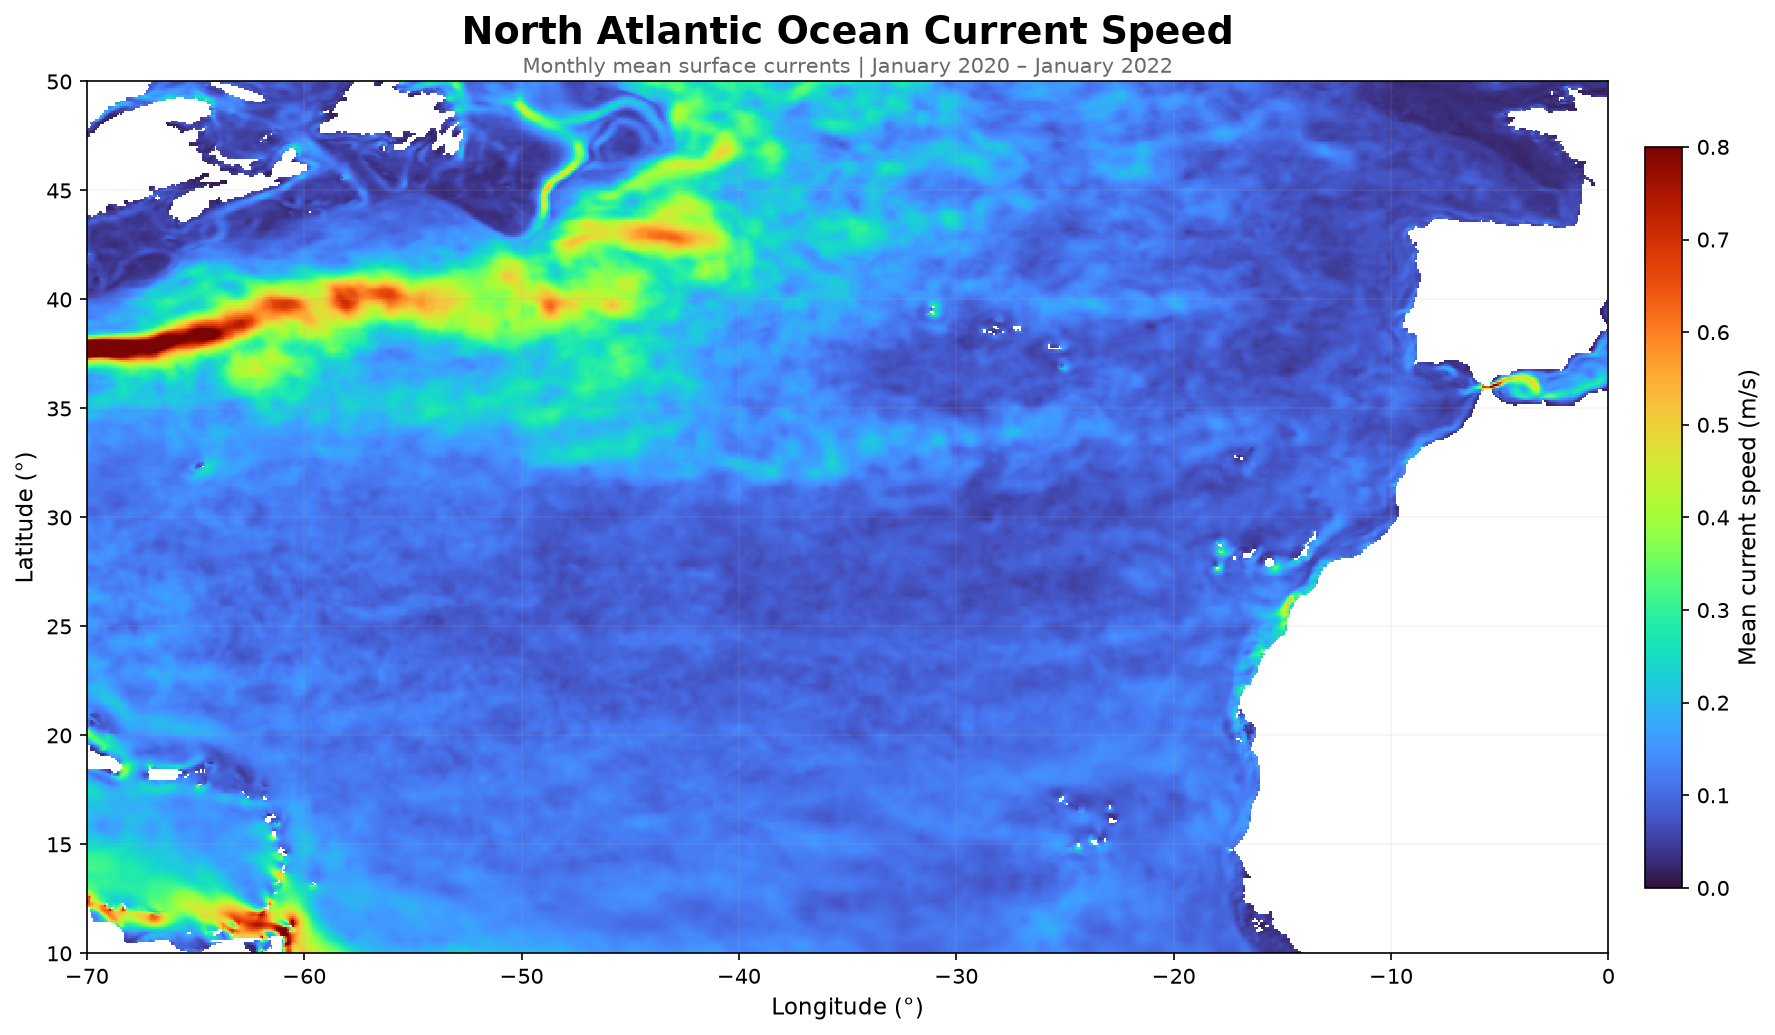

In [33]:
# Average ocean-current speed across 2020–2022
mean_speed = clean_currents["speed"].mean(dim="time")

fig, ax = plt.subplots(figsize=(13, 7), dpi=150)

# Plot ocean-current speed
mesh = ax.pcolormesh(
    mean_speed.longitude,
    mean_speed.latitude,
    mean_speed,
    cmap="turbo",
    shading="auto",
    vmin=0,
    vmax=0.8
)

# Colour bar
cbar = fig.colorbar(mesh, ax=ax, shrink=0.85, pad=0.02)
cbar.set_label("Mean current speed (m/s)", fontsize=11)

# Titles and labels
ax.set_title(
    "North Atlantic Ocean Current Speed",
    fontsize=18,
    fontweight="bold",
    pad=18
)

ax.text(
    0.5, 1.01,
    "Monthly mean surface currents | January 2020 – January 2022",
    transform=ax.transAxes,
    ha="center",
    fontsize=10,
    color="dimgray"
)

ax.set_xlabel("Longitude (°)", fontsize=11)
ax.set_ylabel("Latitude (°)", fontsize=11)

ax.set_xlim(-70, 0)
ax.set_ylim(10, 50)

ax.grid(alpha=0.12)

plt.tight_layout()
plt.show()

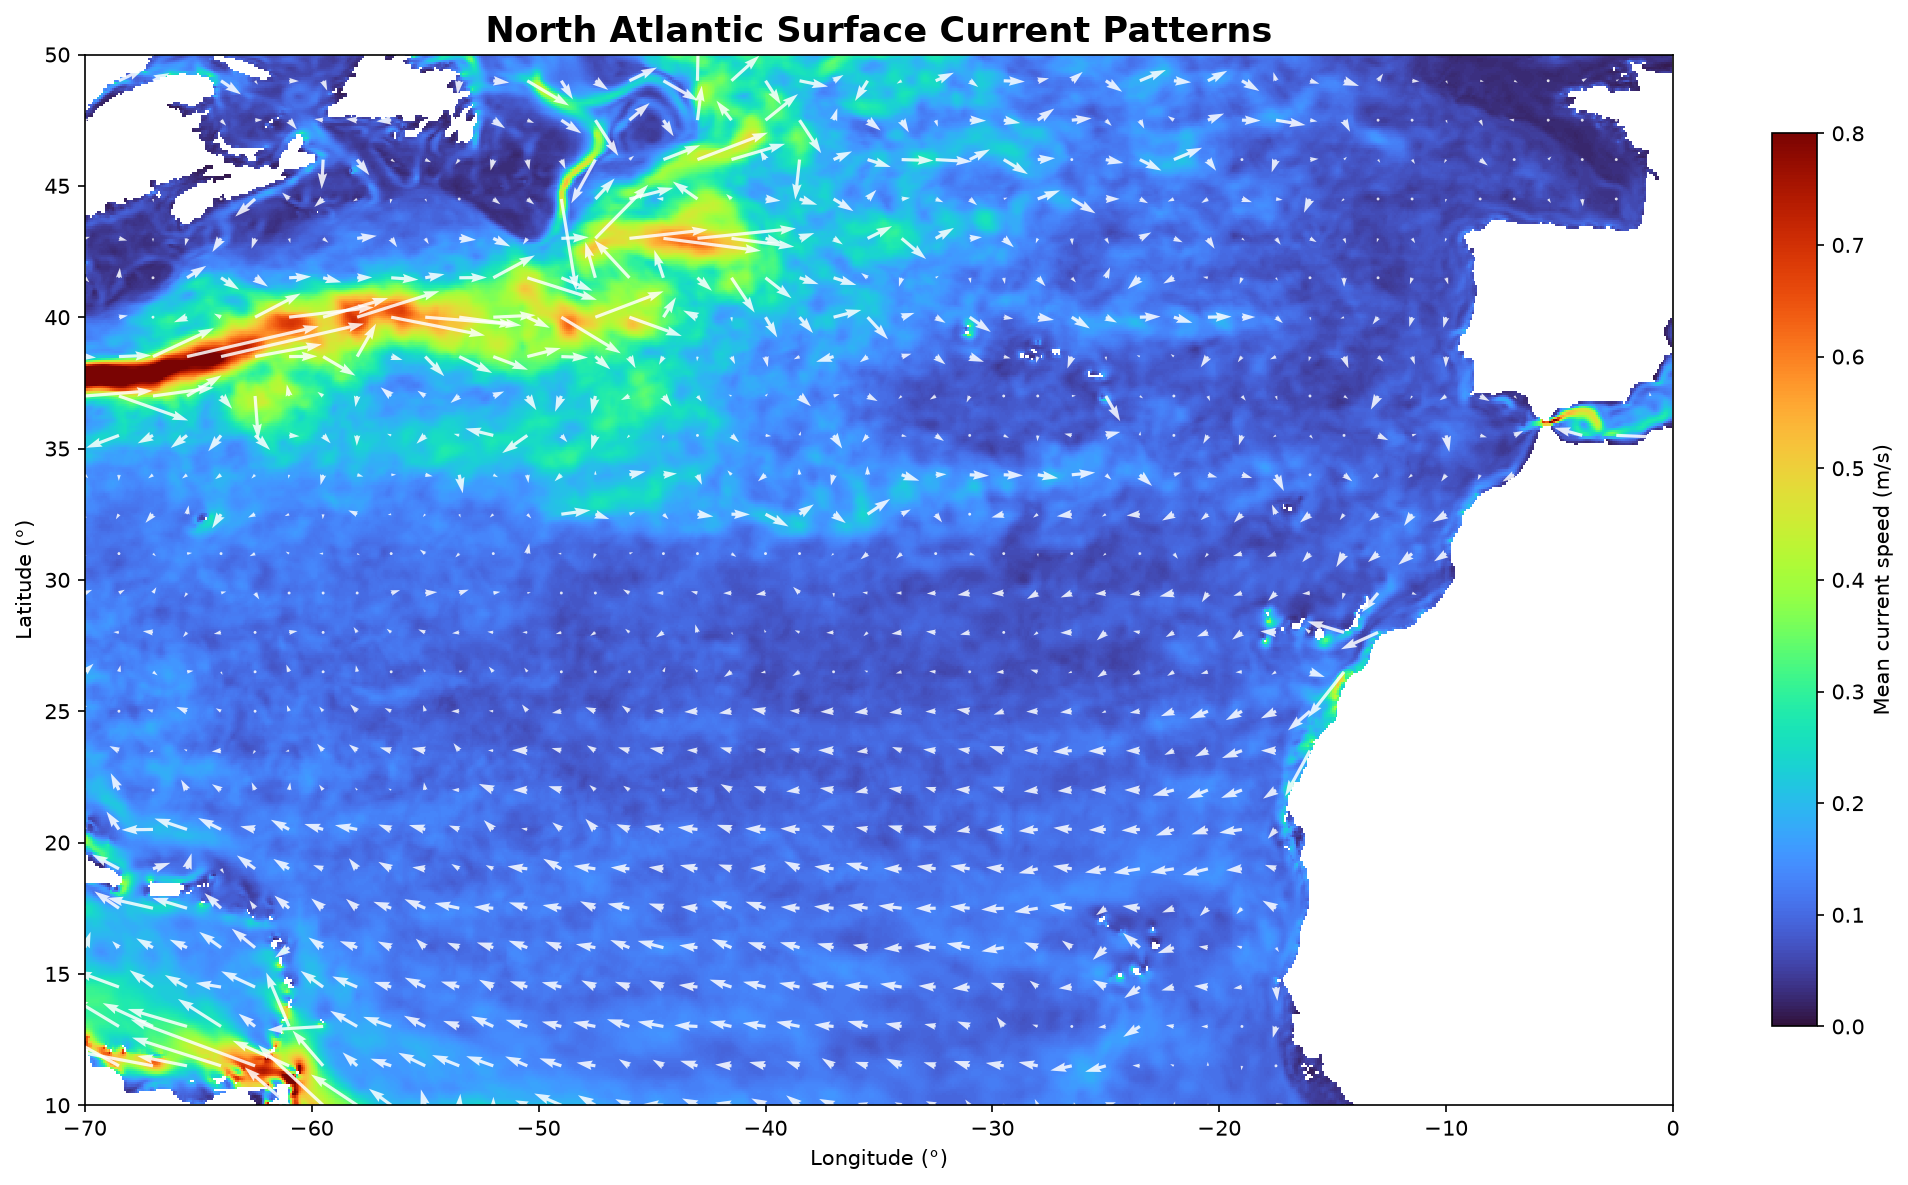

In [34]:
# Average eastward and northward velocities
mean_uo = clean_currents["uo"].mean(dim="time")
mean_vo = clean_currents["vo"].mean(dim="time")

# Reduce arrow density for readability
step = 18

fig, ax = plt.subplots(figsize=(14, 8), dpi=150)

# Background speed map
mesh = ax.pcolormesh(
    mean_speed.longitude,
    mean_speed.latitude,
    mean_speed,
    cmap="turbo",
    shading="auto",
    vmin=0,
    vmax=0.8
)

# Current direction arrows
ax.quiver(
    mean_uo.longitude.values[::step],
    mean_uo.latitude.values[::step],
    mean_uo.values[::step, ::step],
    mean_vo.values[::step, ::step],
    color="white",
    scale=8,
    width=0.002,
    alpha=0.85
)

cbar = fig.colorbar(mesh, ax=ax, shrink=0.85)
cbar.set_label("Mean current speed (m/s)")

ax.set_title(
    "North Atlantic Surface Current Patterns",
    fontsize=17,
    fontweight="bold"
)

ax.set_xlabel("Longitude (°)")
ax.set_ylabel("Latitude (°)")
ax.set_xlim(-70, 0)
ax.set_ylim(10, 50)

plt.tight_layout()
plt.show()

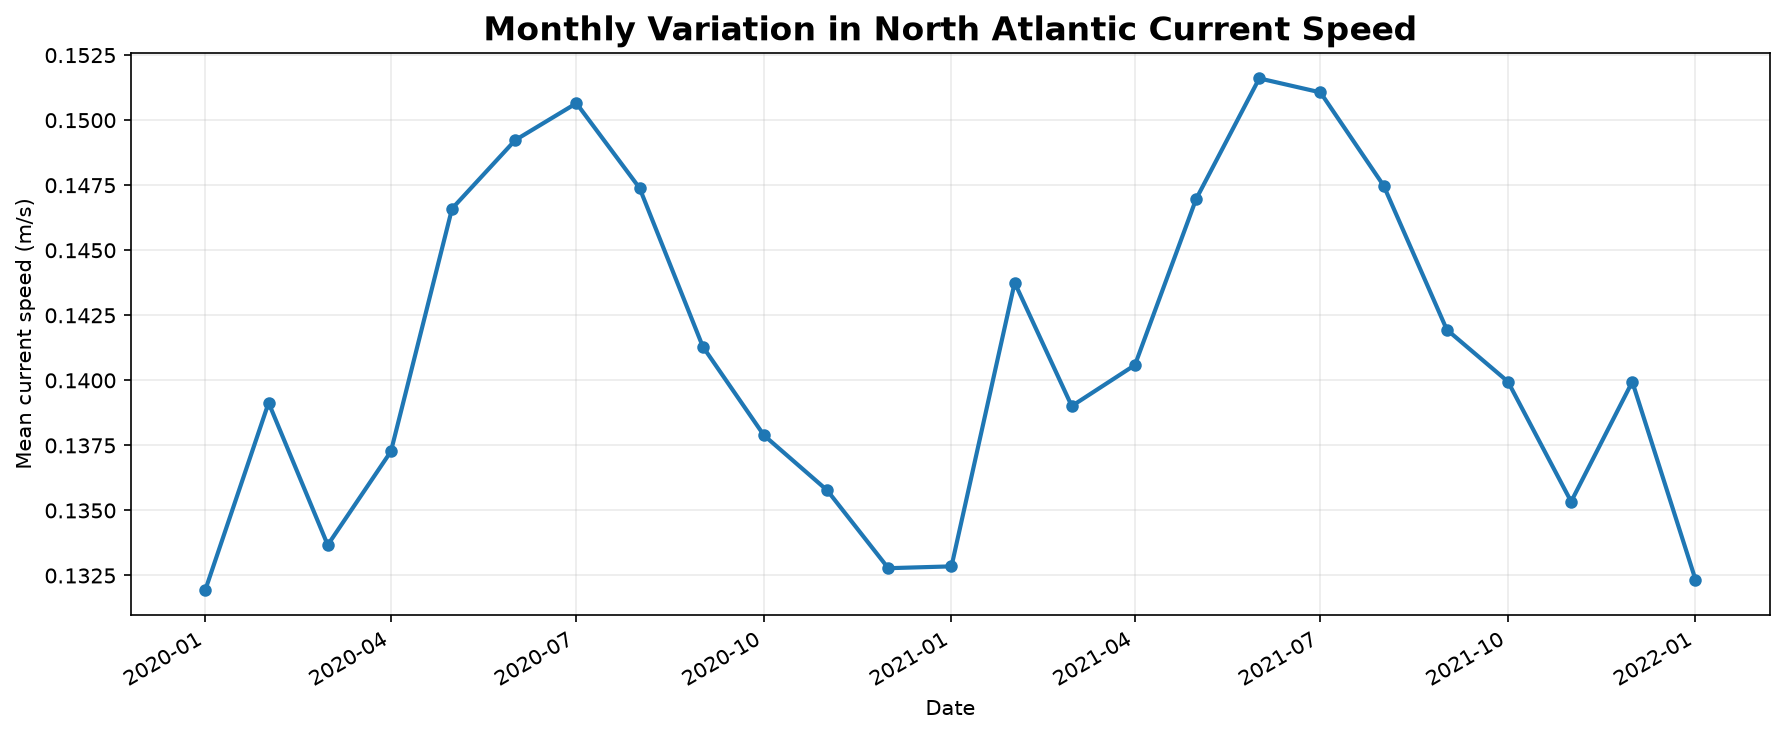

In [35]:
# Calculate spatially averaged current speed for each month
monthly_speed = clean_currents["speed"].mean(
    dim=["latitude", "longitude"]
)

# Convert to DataFrame
monthly_speed_df = monthly_speed.to_dataframe(
    name="Mean current speed"
).reset_index()

# Plot
fig, ax = plt.subplots(figsize=(12, 5), dpi=150)

ax.plot(
    monthly_speed_df["time"],
    monthly_speed_df["Mean current speed"],
    marker="o",
    linewidth=2,
    markersize=5
)

ax.set_title(
    "Monthly Variation in North Atlantic Current Speed",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Date")
ax.set_ylabel("Mean current speed (m/s)")

ax.grid(alpha=0.25)
fig.autofmt_xdate()

plt.tight_layout()
plt.show()

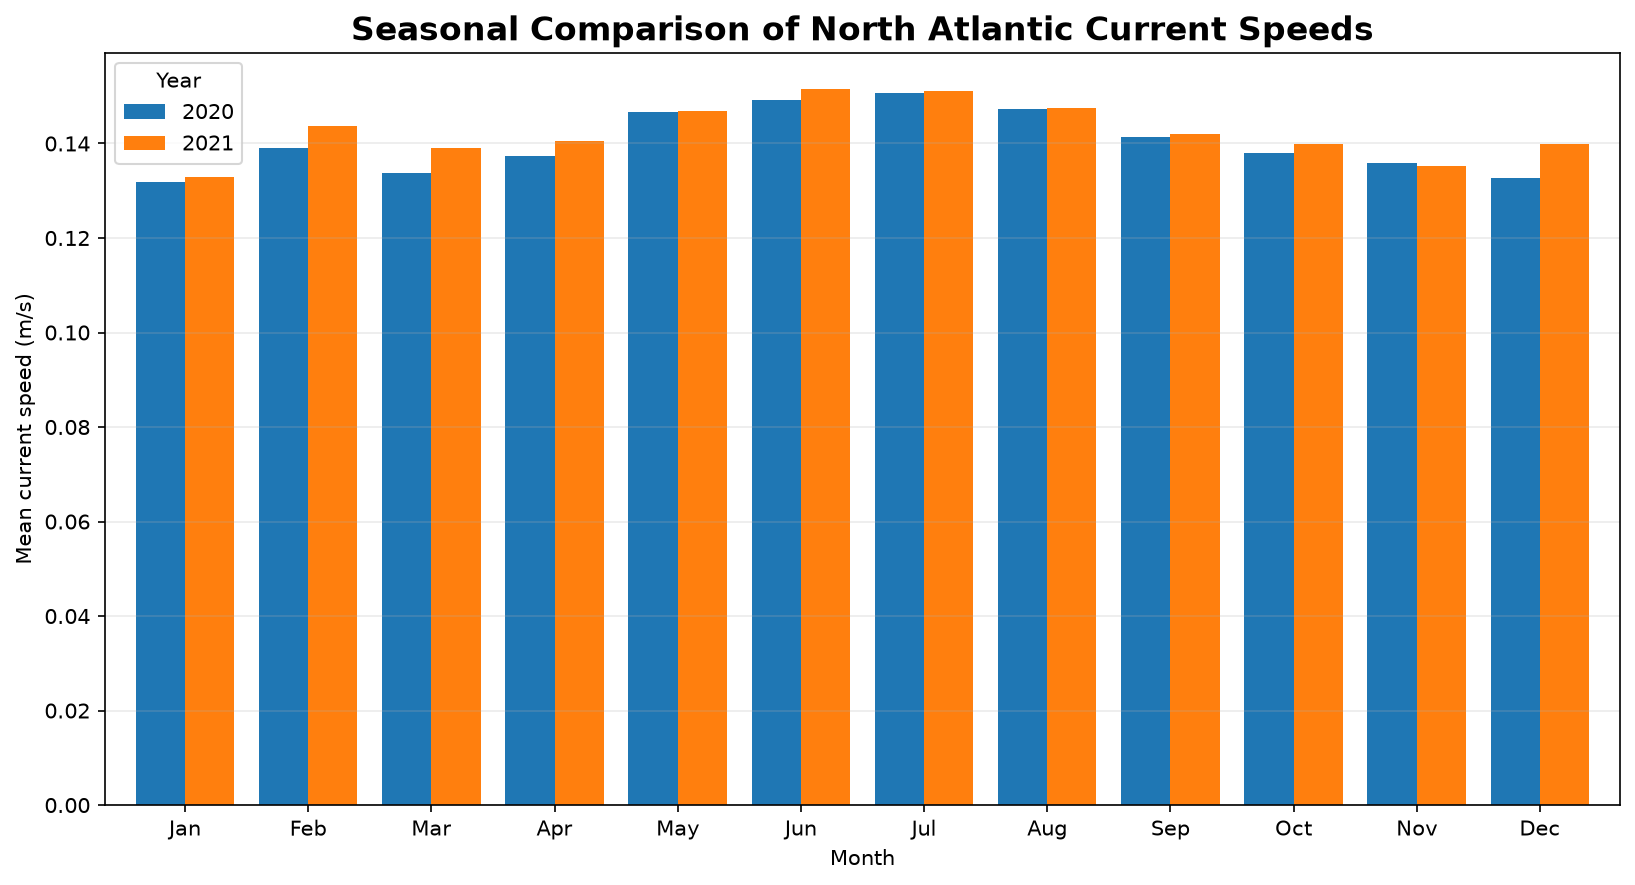

In [36]:
# Extract year and month
monthly_speed_df["year"] = monthly_speed_df["time"].dt.year
monthly_speed_df["month"] = monthly_speed_df["time"].dt.month

# Compare 2020 and 2021
comparison = monthly_speed_df[
    monthly_speed_df["year"].isin([2020, 2021])
].pivot(
    index="month",
    columns="year",
    values="Mean current speed"
)

# Plot comparison
fig, ax = plt.subplots(figsize=(11, 6), dpi=150)

comparison.plot(
    kind="bar",
    ax=ax,
    width=0.8
)

ax.set_title(
    "Seasonal Comparison of North Atlantic Current Speeds",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Month")
ax.set_ylabel("Mean current speed (m/s)")
ax.set_xticklabels(
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
    rotation=0
)

ax.legend(title="Year")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

In [41]:
#assigning microplastic to ocean current

from scipy.spatial import cKDTree

lat_grid, lon_grid = np.meshgrid(
    clean_currents.latitude.values,
    clean_currents.longitude.values,
    indexing="ij"
)

lat_rad = np.radians(lat_grid.ravel())
lon_rad = np.radians(lon_grid.ravel())

grid_xyz = np.column_stack((
    np.cos(lat_rad) * np.cos(lon_rad),
    np.cos(lat_rad) * np.sin(lon_rad),
    np.sin(lat_rad)
))

tree = cKDTree(grid_xyz)

mp_lat = np.radians(df_clean["Latitude"].values)
mp_lon = np.radians(df_clean["Longitude"].values)

mp_xyz = np.column_stack((
    np.cos(mp_lat) * np.cos(mp_lon),
    np.cos(mp_lat) * np.sin(mp_lon),
    np.sin(mp_lat)
))

distances, indices = tree.query(mp_xyz, k=1)

earth_radius_km = 6371

distances_km = (
    2 * earth_radius_km *
    np.arcsin(np.clip(distances / 2, 0, 1))
)

grid_points = np.column_stack((
    lat_grid.ravel(),
    lon_grid.ravel()
))

results_df = pd.DataFrame({
    "index": df_clean.index,
    "MP_lat": df_clean["Latitude"].values,
    "MP_lon": df_clean["Longitude"].values,
    "nearest_lat": grid_points[indices, 0],
    "nearest_lon": grid_points[indices, 1],
    "distance_km": distances_km
})

print(results_df.head())


   index  MP_lat  MP_lon  nearest_lat  nearest_lon  distance_km
0      0  -31.70  -48.56        10.00       -48.58      4636.38
1      1    6.35 -121.85        10.25       -70.00      5715.94
2      2    0.50  -95.35        10.00       -70.00      2995.87
3      3    0.63  -45.40        10.00       -45.42      1041.70
4      4   16.62  -99.70        19.00       -70.00      3151.39


In [27]:
import xarray as xr

currents = xr.open_dataset(
    "cmems_mod_glo_phy_my_0.083deg_P1M-m_1795028217853.nc"
)

print(currents)

<xarray.Dataset> Size: 81MB
Dimensions:    (time: 25, depth: 1, latitude: 481, longitude: 840)
Coordinates:
  * time       (time) datetime64[ns] 200B 2020-01-01 2020-02-01 ... 2022-01-01
  * depth      (depth) float32 4B 0.494
  * latitude   (latitude) float32 2kB 10.0 10.08 10.17 ... 49.83 49.92 50.0
  * longitude  (longitude) float32 3kB -70.0 -69.92 -69.83 ... -0.1667 -0.08332
Data variables:
    uo         (time, depth, latitude, longitude) float32 40MB ...
    vo         (time, depth, latitude, longitude) float32 40MB ...
Attributes:
    Conventions:       CF-1.11
    title:             Monthly mean fields for product GLOBAL_REANALYSIS_PHY_...
    institution:       Mercator Ocean
    producer:          CMEMS - Global Monitoring and Forecasting Centre
    source:            MERCATOR GLORYS12V1
    credit:            E.U. Copernicus Marine Service Information (CMEMS)
    contact:           servicedesk.cmems@mercator-ocean.eu
    references:        http://marine.copernicus.eu
    su

In [28]:
print("mean_uo:", "mean_uo" in globals())
print("mean_vo:", "mean_vo" in globals())
print("mean_speed:", "mean_speed" in globals())

mean_uo: False
mean_vo: False
mean_speed: False


In [29]:
# Calculate average eastward and northward velocities
mean_uo = currents["uo"].mean(dim="time").squeeze()
mean_vo = currents["vo"].mean(dim="time").squeeze()

# Calculate average current speed
mean_speed = np.sqrt(mean_uo**2 + mean_vo**2)

print("Velocity variables calculated successfully!")

Velocity variables calculated successfully!


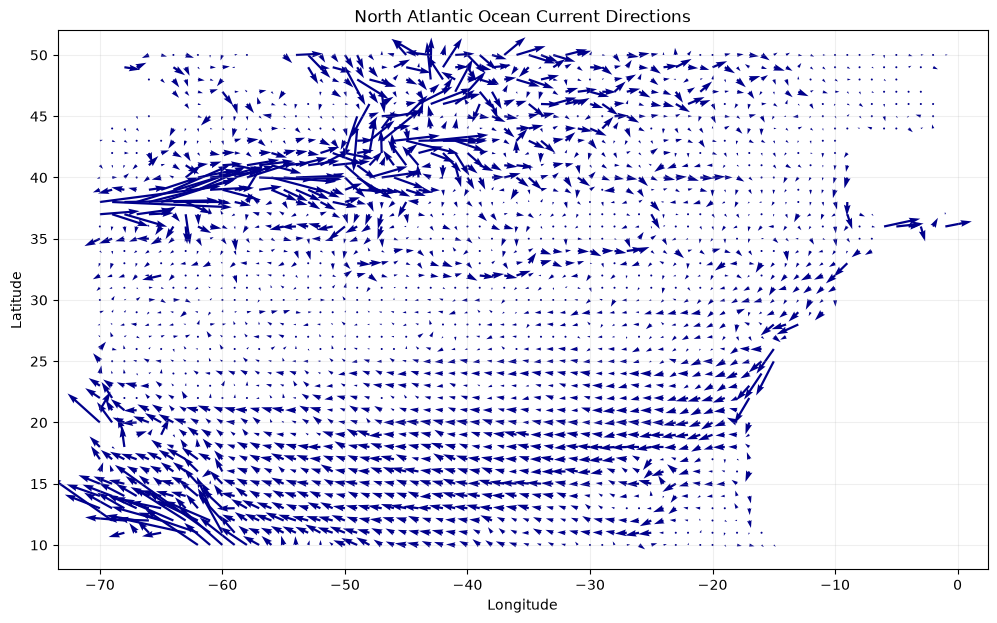

In [30]:
plt.figure(figsize=(12, 7))

plt.quiver(
    currents.longitude.values[::12],
    currents.latitude.values[::12],
    mean_uo.values[::12, ::12],
    mean_vo.values[::12, ::12],
    scale=8,
    color="darkblue"
)

plt.title("North Atlantic Ocean Current Directions")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(alpha=0.2)
plt.show()

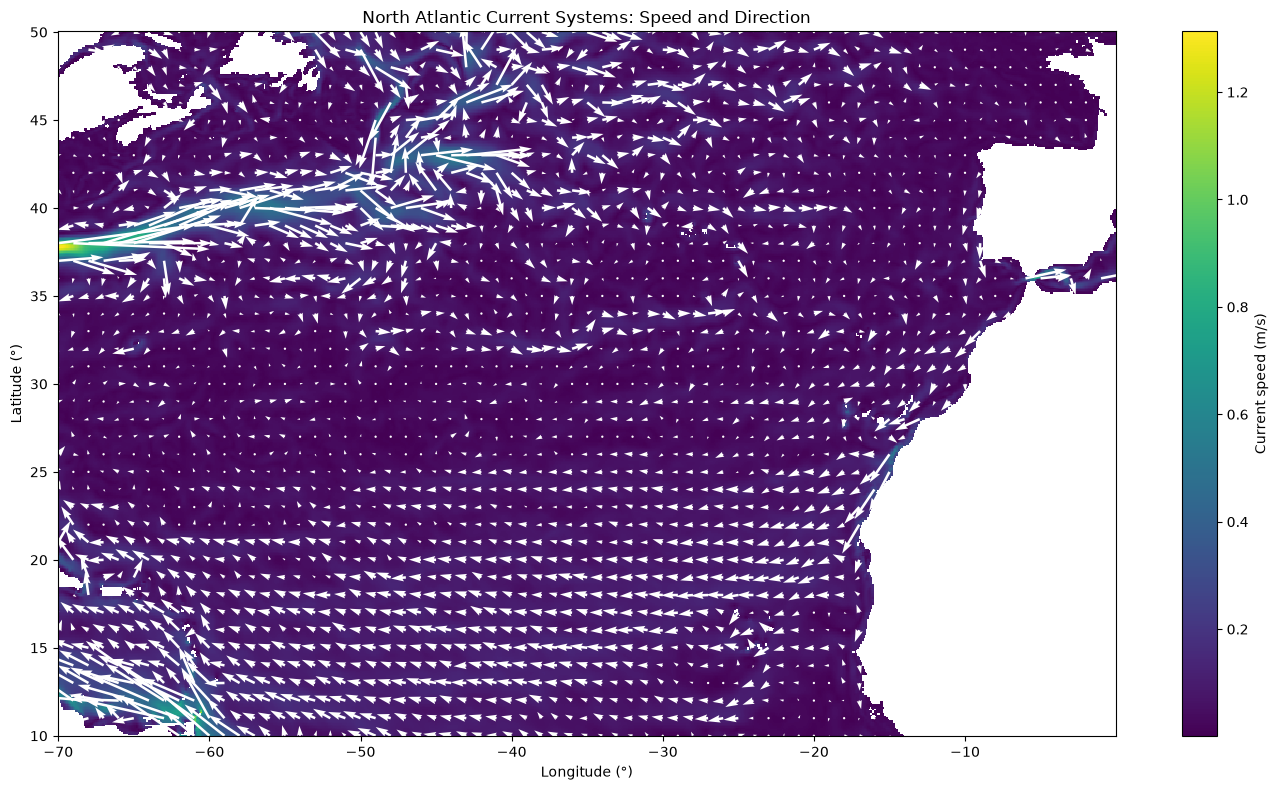

In [32]:
plt.figure(figsize=(14, 8))

plt.pcolormesh(
    currents.longitude,
    currents.latitude,
    mean_speed,
    cmap="viridis",
    shading="auto"
)

plt.colorbar(label="Current speed (m/s)")

plt.quiver(
    currents.longitude.values[::12],
    currents.latitude.values[::12],
    mean_uo.values[::12, ::12],
    mean_vo.values[::12, ::12],
    color="white",
    scale=8
)

plt.title("North Atlantic Current Systems: Speed and Direction")
plt.xlabel("Longitude (°)")
plt.ylabel("Latitude (°)")
plt.tight_layout()
plt.show()

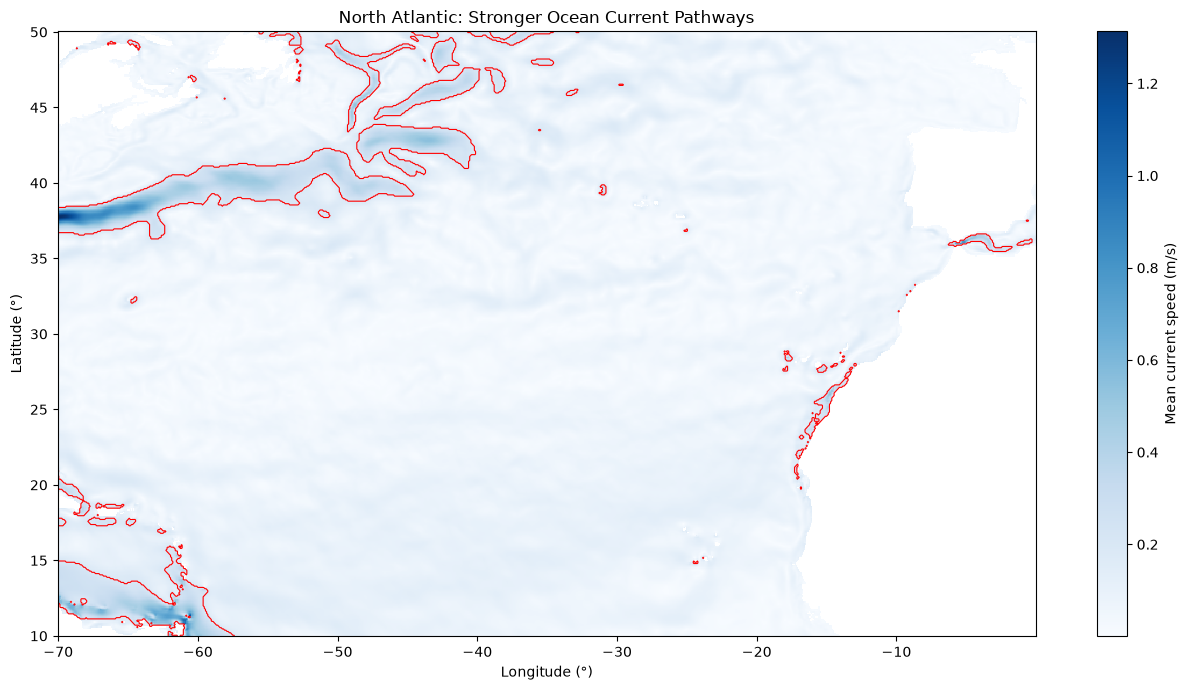

In [35]:
fig, ax = plt.subplots(figsize=(13, 7))

# Plot current speed
speed_plot = ax.pcolormesh(
    currents.longitude,
    currents.latitude,
    mean_speed,
    cmap="Blues",
    shading="auto"
)

# Highlight stronger current regions
ax.contour(
    currents.longitude,
    currents.latitude,
    strong_current.astype(float),
    levels=[0.5],
    colors="red",
    linewidths=0.8
)

# Attach colour bar directly to the speed plot
fig.colorbar(speed_plot, ax=ax, label="Mean current speed (m/s)")

ax.set_title("North Atlantic: Stronger Ocean Current Pathways")
ax.set_xlabel("Longitude (°)")
ax.set_ylabel("Latitude (°)")

plt.tight_layout()
plt.show()

In [37]:
# Select the strong eastward-flowing current region
gulf_stream_mask = (
    (mean_speed > 0.5) &
    (mean_uo > 0) &
    (mean_vo > 0)
)

print("Potential Gulf Stream grid points:",
      int(gulf_stream_mask.sum()))

print("Average speed:",
      float(mean_speed.where(gulf_stream_mask).mean()), "m/s")

Potential Gulf Stream grid points: 956
Average speed: 0.6882820725440979 m/s


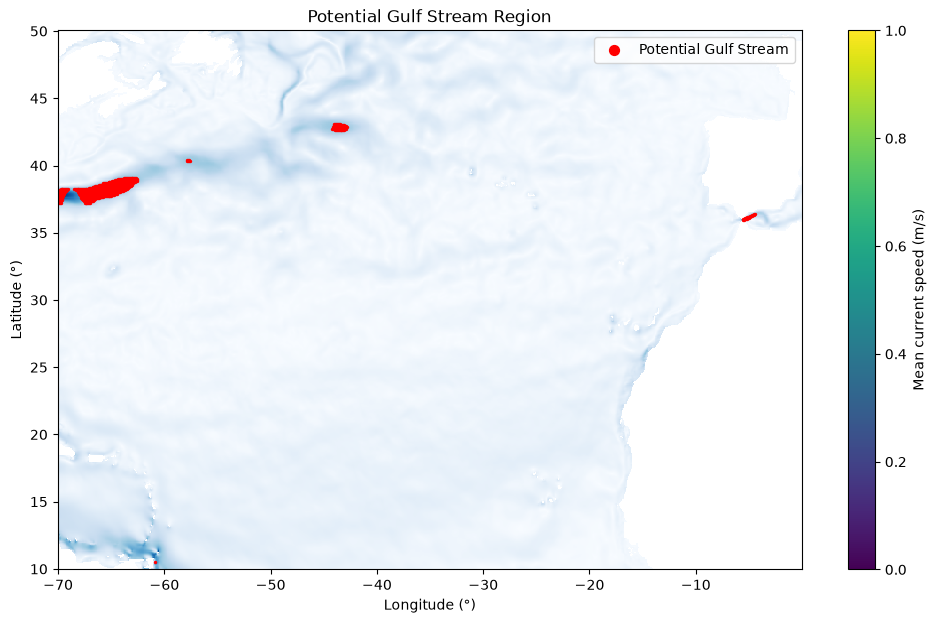

In [62]:
plt.figure(figsize=(12, 7))

plt.pcolormesh(
    currents.longitude,
    currents.latitude,
    mean_speed,
    cmap="Blues",
    shading="auto"
)

plt.scatter(
    mean_speed.longitude.broadcast_like(mean_speed).where(gulf_stream_mask),
    mean_speed.latitude.broadcast_like(mean_speed).where(gulf_stream_mask),
    color="red",
    s=2,
    label="Potential Gulf Stream"
)

plt.colorbar(label="Mean current speed (m/s)")
plt.title("Potential Gulf Stream Region")
plt.xlabel("Longitude (°)")
plt.ylabel("Latitude (°)")
plt.legend(loc="upper right", markerscale=5)
plt.show()

In [61]:
# Group potential strong northeastward currents by latitude
gulf_points["latitude_band"] = pd.cut(
    gulf_points["latitude"],
    bins=[10, 20, 30, 35, 40, 45, 50]
)

print(
    gulf_points.groupby("latitude_band", observed=False)
    .agg(
        number_of_points=("speed", "count"),
        mean_speed=("speed", "mean"),
        mean_longitude=("longitude", "mean")
    )
)

               number_of_points  mean_speed  mean_longitude
latitude_band                                              
(10, 20]                      1        0.73          -60.83
(20, 30]                      0         NaN             NaN
(30, 35]                      0         NaN             NaN
(35, 40]                    869        0.70          -64.20
(40, 45]                     86        0.52          -44.70
(45, 50]                      0         NaN             NaN


In [60]:
# Identify potential North Equatorial Current region

north_equatorial_mask = (
    (mean_speed > 0.2) &
    (mean_uo < 0) &
    (mean_speed.latitude >= 10) &
    (mean_speed.latitude <= 25)
)

print("Potential North Equatorial Current grid points:",
      int(north_equatorial_mask.sum()))

print("Average speed:",
      float(mean_speed.where(north_equatorial_mask).mean()),
      "m/s")

Potential North Equatorial Current grid points: 5208
Average speed: 0.34271135926246643 m/s


In [59]:
# Identify potential Canary Current region

canary_mask = (
    (mean_speed > 0.1) &
    (mean_vo < 0) &
    (mean_speed.latitude >= 15) &
    (mean_speed.latitude <= 35) &
    (mean_speed.longitude >= -20) &
    (mean_speed.longitude <= -5)
)

print("Potential Canary Current grid points:",
      int(canary_mask.sum()))

print("Average speed:",
      float(mean_speed.where(canary_mask).mean()),
      "m/s")

Potential Canary Current grid points: 3136
Average speed: 0.15068750083446503 m/s


In [58]:
# Identify potential Azores Current region

azores_mask = (
    (mean_speed > 0.1) &
    (mean_uo > 0) &
    (mean_speed.latitude >= 30) &
    (mean_speed.latitude <= 40) &
    (mean_speed.longitude >= -40) &
    (mean_speed.longitude <= -20)
)

print("Potential Azores Current grid points:",
      int(azores_mask.sum()))

print("Average speed:",
      float(mean_speed.where(azores_mask).mean()),
      "m/s")

Potential Azores Current grid points: 2048
Average speed: 0.11821500211954117 m/s


In [57]:
# Check overlaps between candidate current regions

masks = {
    "Gulf Stream": gulf_stream_mask,
    "North Equatorial": north_equatorial_mask,
    "Canary": canary_mask,
    "Azores": azores_mask
}

names = list(masks.keys())

for i in range(len(names)):
    for j in range(i + 1, len(names)):
        overlap = masks[names[i]] & masks[names[j]]

        print(
            names[i], "and", names[j],
            "overlap:", int(overlap.sum()), "grid points"
        )

Gulf Stream and North Equatorial overlap: 0 grid points
Gulf Stream and Canary overlap: 0 grid points
Gulf Stream and Azores overlap: 0 grid points
North Equatorial and Canary overlap: 0 grid points
North Equatorial and Azores overlap: 0 grid points
Canary and Azores overlap: 0 grid points


In [56]:
# Remove Canary candidate points from North Equatorial classification

north_equatorial_mask = north_equatorial_mask & ~canary_mask

print("North Equatorial points:",
      int(north_equatorial_mask.sum()))

print("Canary points:",
      int(canary_mask.sum()))

print("Remaining overlap:",
      int((north_equatorial_mask & canary_mask).sum()))

North Equatorial points: 5005
Canary points: 3136
Remaining overlap: 0


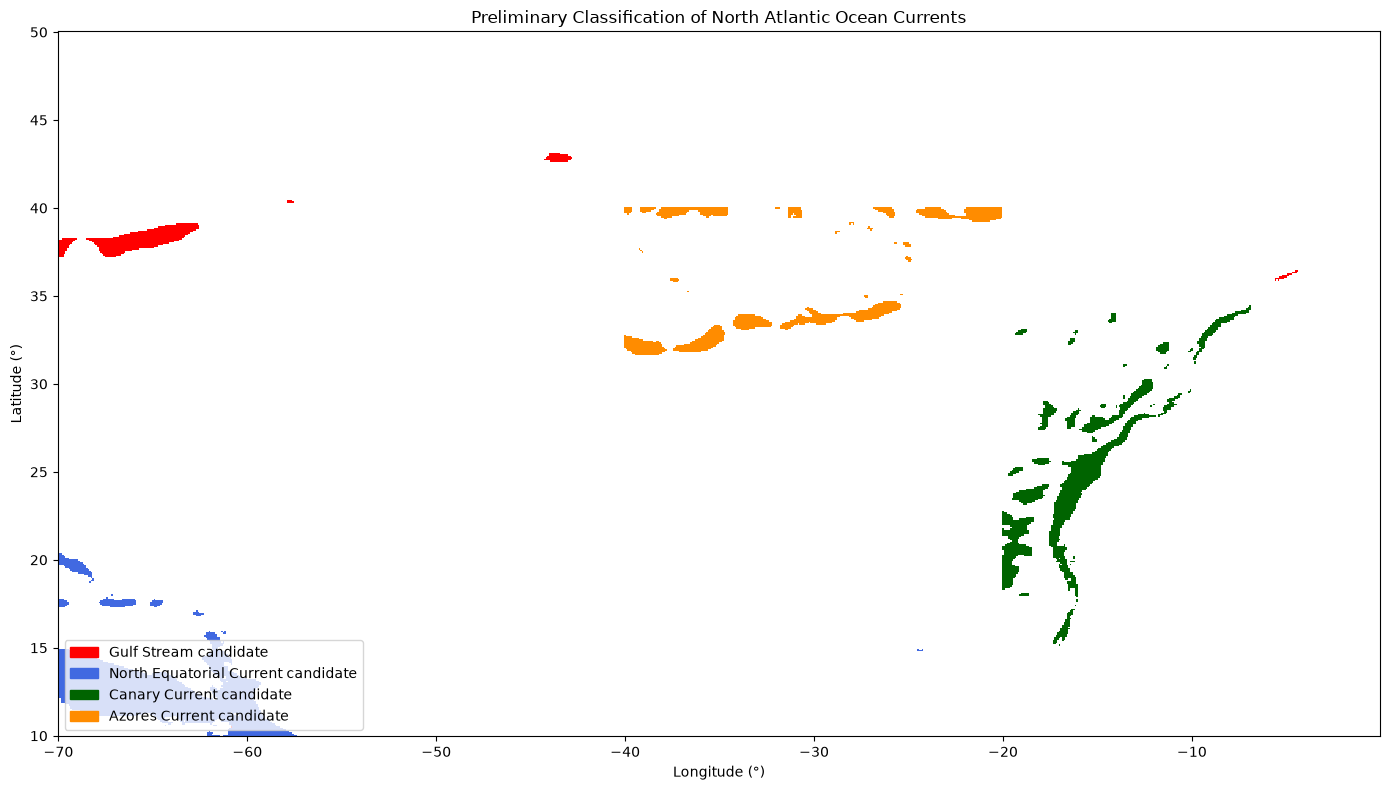

In [55]:
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

# Create classification array
classification = np.full(mean_speed.shape, np.nan)

classification[gulf_stream_mask.values] = 1
classification[north_equatorial_mask.values] = 2
classification[canary_mask.values] = 3
classification[azores_mask.values] = 4

# Define colours
cmap = ListedColormap([
    "red",
    "royalblue",
    "darkgreen",
    "darkorange"
])

norm = BoundaryNorm(
    [0.5, 1.5, 2.5, 3.5, 4.5],
    cmap.N
)

# Plot map
fig, ax = plt.subplots(figsize=(14, 8))

ax.pcolormesh(
    currents.longitude,
    currents.latitude,
    classification,
    cmap=cmap,
    norm=norm,
    shading="auto"
)

# Add legend
legend_items = [
    Patch(color="red", label="Gulf Stream candidate"),
    Patch(color="royalblue", label="North Equatorial Current candidate"),
    Patch(color="darkgreen", label="Canary Current candidate"),
    Patch(color="darkorange", label="Azores Current candidate")
]

ax.legend(handles=legend_items, loc="lower left")

ax.set_title("Preliminary Classification of North Atlantic Ocean Currents")
ax.set_xlabel("Longitude (°)")
ax.set_ylabel("Latitude (°)")

plt.tight_layout()
plt.show()

In [52]:
for name, mask in masks.items():
    speed_values = mean_speed.where(mask)

    print("\n", name)
    print("Grid points:", int(mask.sum()))
    print("Mean speed:", round(float(speed_values.mean()), 3), "m/s")
    print("Mean eastward velocity:", round(float(mean_uo.where(mask).mean()), 3))
    print("Mean northward velocity:", round(float(mean_vo.where(mask).mean()), 3))


 Gulf Stream
Grid points: 956
Mean speed: 0.688 m/s
Mean eastward velocity: 0.666
Mean northward velocity: 0.151

 North Equatorial
Grid points: 5005
Mean speed: 0.347 m/s
Mean eastward velocity: -0.291
Mean northward velocity: 0.158

 Canary
Grid points: 3136
Mean speed: 0.151 m/s
Mean eastward velocity: -0.099
Mean northward velocity: -0.096

 Azores
Grid points: 2048
Mean speed: 0.118 m/s
Mean eastward velocity: 0.105
Mean northward velocity: -0.008


In [54]:
masks = {
    "Gulf Stream": gulf_stream_mask,
    "North Equatorial": north_equatorial_mask,
    "Canary": canary_mask,
    "Azores": azores_mask
}